# Problem Analysis Workshop C — Transformation/Linear Regression

**Course:** PROG8431 — Data Analysis, Mathematics, Modeling and Algorithms

**Team Members:**
- Ubaid Ullah — 9110715
- Rangeetha — 9081357
- Koushik Balne — 9087547




## Problem Analysis Statement

Nitrogen (N) is one of the main soil nutrients, and the soil N level at which crops grow well varies widely. In our data, average N ranges from about 19 for lentil and pomegranate to about 118 for cotton. Our dataset records these levels but does not explain why they differ between crops.

**Problem:** we do not know which crop characteristics and growing conditions are associated with the soil nitrogen (N) level recorded for each crop, or how accurately N can be predicted for observations the model has not seen.

**Objective:** identify the variables that explain N in our dataset and measure how well a regression model predicts it on held-out test data.

**Scope:** the Crop Analyzer project data, augmented with outside sources and analysed with transformations, train/test validation and linear regression. The results describe associations within this dataset; they are not fertilizer recommendations.

### Approach

- **Data:** the Crop Recommendation dataset (2,200 rows, 22 crops × 100) with soil nutrients (N, P, K), temperature, humidity, pH and rainfall.
- **Augmentation:** FAO EcoCrop growing requirements and Statistics Canada crop area and farm value, joined on crop name, giving a study file of **27 usable variables (47 columns after dummy coding)**.
- **Method:** an 80/20 train/test split, two simple linear regressions, then a multiple linear regression narrowed down with backward selection.

## How Transformations and Regression Help the Project

Together they take the Crop Analyzer from describing the data (what each crop's conditions look like) to prediction (what soil N level is expected for a crop, and which variables are associated with it). That is the step from descriptive to predictive analysis.

| Technique | What it does | How it helps our project |
| --- | --- | --- |
| Box-Cox / Tukey's ladder | Reshapes skewed variables toward a normal distribution | K (skew 2.4), P, rainfall and humidity are skewed; apple and grapes sit near K = 200. Transforming them reduces the pull of those extreme crops. |
| log(x + 1) | Compresses values that are mostly zero | The Canadian area and value columns can enter the model even though most of our crops have no matching record (0) in the selected Statistics Canada tables. |
| Dummy and ordinal coding | Turns categories into numbers a regression can use | The crop name becomes 21 dummy variables and the pH class becomes an ordered code. |
| Simple linear regression | Measures one predictor's association with N | Shows that legumes grow at about 36 N lower than other crops, with a clear biological reason. |
| Multiple linear regression + backward selection | Combines several predictors, keeping only those that contribute | Explains N from crop traits and field conditions together, using the simplest model that fits. |
| Train/test validation (RMSE) | Measures error on observations the model has not seen | Tells us how far off a prediction is likely to be (about 34 N for the best single predictor), so we know how much to trust it. |

The result is a short, tested list of the variables associated with a crop's nitrogen level in our dataset, for use in later stages of the project.

## 1. Environment Setup


Use Python 3.12 or later. Keep this notebook beside `requirements.txt` and the `data` folder. Install the packages once using the commented cell below, then restart the kernel and select **Run All**. A working internet connection is needed only for installation or source verification; the packaged CSV supports offline use.



In [1]:
# Run this line once if packages are missing, then restart the kernel.
# %pip install -r requirements.txt

#### Coding Set Up

Start by clearing all output and workspace.

In [2]:
# Clear plots
import matplotlib.pyplot as plt
plt.close('all')

# Clear console
from IPython.display import clear_output
clear_output()

# Clean workspace
%reset -f

import pandas as pd
pd.set_option('display.float_format', lambda x: f'{x:.6f}')

Import Necessary Packages

In [3]:
import os
import re
import zipfile
import urllib.request

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp, chi2_contingency, spearmanr, boxcox
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

import statsmodels.api as sm
import statsmodels.formula.api as smf

from IPython.display import display

#### Configuration

All file locations, download links and fixed settings live in this one cell.

* `CROP_FILE` – our project dataset. Put `Crop_recommendation.csv` in the same folder as this notebook (or change the path).
* External files are downloaded **once** into `data/` and re-used on later runs. If your network blocks a download, download the file manually from the URL shown and save it in `data/` under the file name shown — the notebook will then use the local copy.
* `RANDOM_STATE = 6174` matches the class MLR demo so the split is reproducible.

In [4]:
# Set up number displays
pd.set_option('display.precision', 5)
pd.set_option('display.max_columns', 80)
np.set_printoptions(suppress=True)

CROP_FILE = "Crop_recommendation.csv"
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

SOURCES = {
    # FAO EcoCrop database (full copy published in the OpenCLIM/ecocrop GitHub repository)
    "ecocrop": ("https://raw.githubusercontent.com/OpenCLIM/ecocrop/main/EcoCrop_DB.csv",
                "EcoCrop_DB.csv"),
    # Statistics Canada 32-10-0359-01: area, yield, production, price and farm value of principal field crops
    "statcan_field": ("https://www150.statcan.gc.ca/n1/tbl/csv/32100359-eng.zip",
                      "32100359-eng.zip"),
    # Statistics Canada 32-10-0364-01: area, production and farm gate value of marketed fruits
    "statcan_fruit": ("https://www150.statcan.gc.ca/n1/tbl/csv/32100364-eng.zip",
                      "32100364-eng.zip"),
    # Statistics Canada 32-10-0365-01: area, production and farm gate value of marketed vegetables (melons)
    "statcan_veg": ("https://www150.statcan.gc.ca/n1/tbl/csv/32100365-eng.zip",
                    "32100365-eng.zip"),
}

STATCAN_YEARS = 5          # average of the most recent 5 years
RANDOM_STATE = 6174        # random seed for reproducibility
TEST_SIZE = 0.20           # 80/20 split, as in the class demo
ALPHA = 0.05               # significance level for all tests

def rmse(actual, predicted):  
    # Root mean squared error, used to compare models on the training and test sets  
    return np.sqrt(mean_squared_error(actual, predicted))  

def get_source(key):
    # Return the local path of a source file, downloading it on first use.
    url, fname = SOURCES[key]
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        print(f"Downloading {fname} ...")
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=120) as r, open(path, "wb") as f:
                f.write(r.read())
        except Exception as e:
            raise RuntimeError(
                f"Could not download {url}\n({e})\n"
                f"Download it manually and save it as {path}, then re-run this cell."
            )
    return path

## 2. Data Augmentation

### 2.1 Primary dataset – Crop Recommendation

In [5]:
crop = pd.read_csv(CROP_FILE)

print("Original Crop Structure:")
crop.info()

# Consistent, short names (same idea as the rename step in the class demos)
crop.columns = [c.strip() for c in crop.columns]
crop = crop.rename(columns={"temperature": "temp", "humidity": "humid", "rainfall": "rain"})
crop["label"] = crop["label"].str.strip().str.lower()

print("\nRenamed Crop Structure:")
crop.info()

print("\nRows per crop:")
print(crop["label"].value_counts().sort_index())
print("\nMissing values per column:")
print(crop.isna().sum())

Original Crop Structure:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB

Renamed Crop Structure:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   N       2200 non-null   int64  
 1   P       2200 non-null   int64  
 2   K       2200 non-null   int64  
 3   temp    2200 non-null   float64
 4   humid   2200 non-null   float64
 5   ph      2200 non

### 2.2 External source 1 – FAO EcoCrop (crop environmental requirements)

For each of our 22 crops we pull FAO's published growing requirements: optimal and absolute temperature (°C), optimal and absolute annual rainfall (mm), optimal and absolute soil pH, crop cycle length (days), life form and crop category. Crops are matched by **scientific name**, which is unambiguous, rather than by common name.

**Note on life form and category:** both were requested, but FAO left them blank for **maize**. Section 2.5 drops any field that is missing for one of our crops, so both are removed.

**Note on crop cycle** FAO records **watermelon's crop cycle as 0–0 days**, a placeholder rather than a real value. The code now treats a 0-day cycle as missing, so under the same rule both crop-cycle fields (`eco_cycle_min`, `eco_cycle_max`) are also dropped. The study file keeps the remaining 12 numeric FAO requirements plus the derived `eco_topt_width`.

In [6]:
# Our crop name -> scientific name used in FAO EcoCrop
ECOCROP_NAMES = {
    "rice": "Oryza sativa",            "maize": "Zea mays",
    "chickpea": "Cicer arietinum",     "kidneybeans": "Phaseolus vulgaris",
    "pigeonpeas": "Cajanus cajan",     "mothbeans": "Vigna aconitifolia",
    "mungbean": "Vigna radiata",       "blackgram": "Vigna mungo",
    "lentil": "Lens culinaris",        "pomegranate": "Punica granatum",
    "banana": "Musa acuminata",        "mango": "Mangifera indica",
    "grapes": "Vitis vinifera",        "watermelon": "Citrullus lanatus",
    "muskmelon": "Cucumis melo",       "apple": "Malus domestica",
    "orange": "Citrus sinensis",       "papaya": "Carica papaya",
    "coconut": "Cocos nucifera",       "cotton": "Gossypium hirsutum",
    "jute": "Corchorus capsularis",    "coffee": "Coffea arabica",
}

# EcoCrop field codes -> our names
ECO_NUMERIC = {
    "TOPMN": "eco_topt_min", "TOPMX": "eco_topt_max",      # optimal temperature (deg C)
    "TMIN":  "eco_tabs_min", "TMAX":  "eco_tabs_max",      # absolute temperature (deg C)
    "ROPMN": "eco_ropt_min", "ROPMX": "eco_ropt_max",      # optimal annual rainfall (mm)
    "RMIN":  "eco_rabs_min", "RMAX":  "eco_rabs_max",      # absolute annual rainfall (mm)
    "PHOPMN": "eco_phopt_min", "PHOPMX": "eco_phopt_max",  # optimal soil pH
    "PHMIN": "eco_phabs_min", "PHMAX": "eco_phabs_max",    # absolute soil pH
    "GMIN":  "eco_cycle_min", "GMAX":  "eco_cycle_max",    # crop cycle (days)
}
ECO_CATEGORICAL = {"LIFO": "life_form", "CAT": "eco_category"}

eco_raw = pd.read_csv(get_source("ecocrop"), encoding="latin-1", low_memory=False)
eco_raw = eco_raw[eco_raw["ScientificName"].isin(ECOCROP_NAMES.values())]

not_matched = set(ECOCROP_NAMES.values()) - set(eco_raw["ScientificName"])
if not_matched:
    raise ValueError(f"No EcoCrop record found for: {not_matched}. Check ECOCROP_NAMES.")

names = pd.DataFrame({"label": list(ECOCROP_NAMES), "ScientificName": list(ECOCROP_NAMES.values())})
eco = (names.merge(eco_raw[["ScientificName"] + list(ECO_NUMERIC) + list(ECO_CATEGORICAL)],
                   on="ScientificName", how="left", validate="one_to_one")
            .rename(columns={"ScientificName": "eco_scientific_name", **ECO_NUMERIC, **ECO_CATEGORICAL}))

for c in ECO_NUMERIC.values():
    eco[c] = pd.to_numeric(eco[c], errors="coerce")

# A crop cycle of 0 days is a placeholder in EcoCrop, not a real value, so it is treated as missing
for c in ["eco_cycle_min", "eco_cycle_max"]:
    zero_cycle = eco[c] <= 0
    if zero_cycle.any():
        print(f"{c}: 0 days for {eco.loc[zero_cycle, 'label'].tolist()} -> treated as missing")
    eco.loc[zero_cycle, c] = np.nan

display(eco)
print("\nMissing EcoCrop values per field:")
print(eco.isna().sum()[eco.isna().sum() > 0])

eco_cycle_min: 0 days for ['watermelon'] -> treated as missing
eco_cycle_max: 0 days for ['watermelon'] -> treated as missing


,label,eco_scientific_name,eco_topt_min,eco_topt_max,eco_tabs_min,eco_tabs_max,eco_ropt_min,eco_ropt_max,eco_rabs_min,eco_rabs_max,eco_phopt_min,eco_phopt_max,eco_phabs_min,eco_phabs_max,eco_cycle_min,eco_cycle_max,life_form,eco_category
0,rice,Oryza sativa,20.000000,30.000000,10.000000,36.000000,1500.000000,2000.000000,1000.000000,4000.000000,5.500000,7.000000,4.500000,9.000000,80.000000,180.000000,grass,cereals & pseudocereals
1,maize,Zea mays,18.000000,33.000000,10.000000,47.000000,600.000000,1200.000000,400.000000,1800.000000,5.000000,7.000000,4.500000,8.500000,65.000000,365.000000,NaN,NaN
2,chickpea,Cicer arietinum,15.000000,29.000000,7.000000,35.000000,600.000000,1000.000000,300.000000,1800.000000,6.000000,8.500000,4.700000,9.500000,90.000000,180.000000,herb,pulses (grain legumes)
3,kidneybeans,Phaseolus vulgaris,16.000000,25.000000,7.000000,32.000000,500.000000,2000.000000,300.000000,4300.000000,5.500000,7.500000,4.000000,9.000000,50.000000,270.000000,herb,"pulses (grain legumes), forage/pasture, vegeta..."
4,pigeonpeas,Cajanus cajan,18.000000,38.000000,10.000000,45.000000,600.000000,1500.000000,400.000000,4000.000000,5.000000,7.000000,4.500000,8.400000,90.000000,365.000000,shrub,vegetables
5,mothbeans,Vigna aconitifolia,24.000000,32.000000,13.000000,45.000000,500.000000,900.000000,400.000000,2500.000000,6.500000,7.500000,5.000000,8.000000,60.000000,90.000000,herb,"pulses (grain legumes), forage/pasture, vegeta..."
6,mungbean,Vigna radiata,21.000000,36.000000,8.000000,40.000000,650.000000,900.000000,500.000000,1250.000000,5.500000,6.200000,4.300000,8.300000,50.000000,120.000000,"herb, vine, sub-shrub","pulses (grain legumes), forage/pasture, cover ..."
7,blackgram,Vigna mungo,22.000000,35.000000,8.000000,40.000000,650.000000,900.000000,530.000000,2430.000000,5.500000,6.500000,4.500000,7.500000,60.000000,130.000000,herb,"pulses (grain legumes), forage/pasture, medici..."
8,lentil,Lens culinaris,15.000000,29.000000,5.000000,32.000000,600.000000,1000.000000,250.000000,2500.000000,5.500000,7.500000,4.500000,8.200000,70.000000,240.000000,herb,"pulses (grain legumes), medicinals & aromatic"
9,pomegranate,Punica granatum,23.000000,32.000000,8.000000,40.000000,900.000000,1200.000000,400.000000,4200.000000,6.500000,7.500000,5.800000,8.500000,180.000000,365.000000,"shrub, tree","fruits & nuts, medicinals & aromatic"



Missing EcoCrop values per field:
eco_cycle_min    1
eco_cycle_max    1
life_form        1
eco_category     1
dtype: int64


### 2.3 External source 2 – Statistics Canada (crops matched in the selected tables)

Statistics Canada publishes harvested or cultivated area and farm value by crop. We use three of its tables: field crops (32-10-0359-01), fruits (32-10-0364-01) and vegetables (32-10-0365-01). Eight of our 22 crops have a matching row in these tables, and for each crop we record:

* `grown_in_canada` – 1 if the crop has a matching row with a positive area, else 0
* `ca_area_ha` – average harvested or cultivated area (hectares) over each table's latest 5 years; 0 if not matched
* `ca_farm_value` – average farm (gate) value (dollars) over the same years; 0 if not matched or not published for those years

**How crops are matched.** The code lists the exact Statistics Canada row used for each crop, so every match can be checked against the source table:

| Our crop | Table | Statistics Canada row |
|---|---|---|
| maize, chickpea, lentil, kidneybeans | Field crops | Corn for grain; Chick peas; Lentils; Beans, all dry (white and coloured) |
| apple, grapes | Fruits | Fresh apples; Fresh grapes (the total, not the Labrusca or vinifera sub-types) |
| watermelon, muskmelon | Vegetables | Fresh watermelons; Other fresh melons (the table has no muskmelon row, so this is the closest category) |

**What a zero means.** A 0 means the crop was **not matched in the selected Statistics Canada tables**. For most of our crops (rice, mango, coffee, cotton and other tropical crops) this is because they are not grown commercially in Canada, but a 0 can also mean the crop is reported under a different name or in a table we did not use. A 0 should therefore be read as "no matching record in these tables", not as a measured production of zero.

**Field-crop farm values.** Statistics Canada has not published farm values for field crops since 1984, so maize, chickpea, lentil and kidney beans have an area but a farm value of 0 for the latest 5 years.

In [7]:
SCALE = {"units": 1, "thousands": 1e3, "millions": 1e6}

# Column that holds the crop name and column that holds the measure, in each table
TABLE_COLUMNS = {"field": ("Type of crop", "Harvest disposition"),
                 "fruit": ("Commodity", "Estimates"),
                 "veg":   ("Commodity", "Estimates")}

# Our crop -> (table, exact crop row, exact area row, exact farm-value row)
STATCAN_ROWS = {
    "maize":       ("field", "Corn for grain", "Harvested area (hectares)", "Total farm value (dollars)"),
    "chickpea":    ("field", "Chick peas", "Harvested area (hectares)", "Total farm value (dollars)"),
    "lentil":      ("field", "Lentils", "Harvested area (hectares)", "Total farm value (dollars)"),
    "kidneybeans": ("field", "Beans, all dry (white and coloured)", "Harvested area (hectares)", "Total farm value (dollars)"),
    "apple":       ("fruit", "Fresh apples [114114111]", "Cultivated area, total", "Farm gate value"),
    "grapes":      ("fruit", "Fresh grapes [1141147]", "Cultivated area, total", "Farm gate value"),
    "watermelon":  ("veg",   "Fresh watermelons [114221411]", "Area harvested (hectares)", "Farm gate value (dollars)"),
    "muskmelon":   ("veg",   "Other fresh melons [114221421]", "Area harvested (hectares)", "Farm gate value (dollars)"),
}


def load_statcan(key):
    # National rows of a Statistics Canada table, with VALUE in units and a YEAR column
    with zipfile.ZipFile(get_source("statcan_" + key)) as z:
        name = next(n for n in z.namelist() if n.endswith(".csv") and "MetaData" not in n)
        df = pd.read_csv(z.open(name), low_memory=False)
    df = df[df["GEO"] == "Canada"].copy()
    df["VALUE"] = pd.to_numeric(df["VALUE"], errors="coerce") * df["SCALAR_FACTOR"].str.strip().str.lower().map(SCALE)
    df["YEAR"] = df["REF_DATE"].astype(str).str[:4].astype(int)
    return df


def statcan_avg(key, crop_row, measure_row, hectares_only=False):
    # Average yearly value of one exact row over the table's latest STATCAN_YEARS years (0 if none)
    df = tables[key]
    crop_col, measure_col = TABLE_COLUMNS[key]
    rows = df[(df[crop_col] == crop_row) & (df[measure_col] == measure_row)
              & (df["YEAR"] > df["YEAR"].max() - STATCAN_YEARS)].dropna(subset=["VALUE"])
    if hectares_only:              # the fruit table gives area in both acres and hectares
        rows = rows[rows["UOM"] == "Hectares"]
    return rows.groupby("YEAR")["VALUE"].sum().mean() if len(rows) else 0.0


tables = {key: load_statcan(key) for key in TABLE_COLUMNS}

rows = []
for crop_name in ECOCROP_NAMES:
    if crop_name in STATCAN_ROWS:
        key, crop_row, area_row, value_row = STATCAN_ROWS[crop_name]
        last = tables[key]["YEAR"].max()
        rows.append({"label": crop_name,
                     "ca_area_ha": statcan_avg(key, crop_row, area_row, hectares_only=True),
                     "ca_farm_value": statcan_avg(key, crop_row, value_row),
                     "statcan_source": f"{key}: {crop_row} ({last - STATCAN_YEARS + 1}-{last})"})
    else:
        rows.append({"label": crop_name, "ca_area_ha": 0.0, "ca_farm_value": 0.0,
                     "statcan_source": "not matched in the selected tables"})

can = pd.DataFrame(rows)
can["grown_in_canada"] = (can["ca_area_ha"] > 0).astype(int)
display(can)

,label,ca_area_ha,ca_farm_value,statcan_source,grown_in_canada
0,rice,0.000000,0.000000,not matched in the selected tables,0
1,maize,1486340.000000,0.000000,field: Corn for grain (2022-2026),1
2,chickpea,169080.000000,0.000000,field: Chick peas (2022-2026),1
3,kidneybeans,142600.000000,0.000000,"field: Beans, all dry (white and coloured) (20...",1
4,pigeonpeas,0.000000,0.000000,not matched in the selected tables,0
5,mothbeans,0.000000,0.000000,not matched in the selected tables,0
6,mungbean,0.000000,0.000000,not matched in the selected tables,0
7,blackgram,0.000000,0.000000,not matched in the selected tables,0
8,lentil,1633300.000000,0.000000,field: Lentils (2022-2026),1
9,pomegranate,0.000000,0.000000,not matched in the selected tables,0


### 2.4 Merge the sources and create derived variables

The external sources describe **crops**, so they are joined to every row on `label` (a many-to-one merge). We then derive the variables below.

| Derived variable | Definition | Why |
|---|---|---|
| `is_legume` | 1 for chickpea, kidney beans, pigeon peas, moth beans, mung bean, black gram, lentil (family Fabaceae) | Legumes fix their own nitrogen, so they are expected to grow at lower soil N |
| `P_K_ratio` | P / K | Balance of the two nutrients (ratio idea from the validation slides) |
| `eco_topt_width` | FAO optimal max − optimal min temperature | Crop's temperature tolerance |
| `ph_class` | acidic (< 6.5), neutral (6.5–7.5), alkaline (> 7.5) | Standard agronomic pH classes |

In [8]:
LEGUMES = {"chickpea", "kidneybeans", "pigeonpeas", "mothbeans", "mungbean", "blackgram", "lentil"}

df = (crop.merge(eco.drop(columns=["eco_scientific_name"]), on="label", how="left", validate="many_to_one")
          .merge(can.drop(columns=["statcan_source"]), on="label", how="left", validate="many_to_one"))

df["is_legume"] = df["label"].isin(LEGUMES).astype(int)
df["P_K_ratio"] = df["P"] / df["K"]

if {"eco_topt_min", "eco_topt_max"} <= set(df.columns):
    df["eco_topt_width"] = df["eco_topt_max"] - df["eco_topt_min"]

df["ph_class"] = pd.cut(df["ph"], bins=[-np.inf, 6.5, 7.5, np.inf],
                        labels=["acidic", "neutral", "alkaline"], right=False)

print("Merged shape:", df.shape)
print("\nMissing values after merge:")
print(df.isna().sum()[df.isna().sum() > 0])

Merged shape: (2200, 31)

Missing values after merge:
eco_cycle_min    100
eco_cycle_max    100
life_form        100
eco_category     100
dtype: int64


### 2.5 Missing values

Any EcoCrop field that FAO left blank for **any** of our 22 crops is **dropped** rather than filled, so every value in the study file is a real published value. The check is done at crop level (one value per crop).

This removes four fields: life form and category (blank for maize) and the two crop-cycle fields (watermelon's 0-day cycle is treated as missing, see 2.2).

In [9]:
eco_fields = [c for c in df.columns if c.startswith("eco_")] + [c for c in ["life_form"] if c in df]
crop_table = df.groupby("label")[eco_fields].first()
missing_by_field = crop_table.isna().sum()
dropped_fields = missing_by_field[missing_by_field > 0].index.tolist()

for c in dropped_fields:
    print(f"{c}: missing for {missing_by_field[c]} crop(s) -> field dropped")
df = df.drop(columns=dropped_fields)
print("EcoCrop fields dropped:", dropped_fields or "none")
print("EcoCrop fields kept   :", [c for c in eco_fields if c not in dropped_fields])

print("Remaining missing values:", int(df.isna().sum().sum()))

eco_cycle_min: missing for 1 crop(s) -> field dropped
eco_cycle_max: missing for 1 crop(s) -> field dropped
eco_category: missing for 1 crop(s) -> field dropped
life_form: missing for 1 crop(s) -> field dropped
EcoCrop fields dropped: ['eco_cycle_min', 'eco_cycle_max', 'eco_category', 'life_form']
EcoCrop fields kept   : ['eco_topt_min', 'eco_topt_max', 'eco_tabs_min', 'eco_tabs_max', 'eco_ropt_min', 'eco_ropt_max', 'eco_rabs_min', 'eco_rabs_max', 'eco_phopt_min', 'eco_phopt_max', 'eco_phabs_min', 'eco_phabs_max', 'eco_topt_width']
Remaining missing values: 0


### 2.6 Descriptive measures and visualizations

,N,P,K,temp,humid,ph,rain,P_K_ratio
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655,1.668555
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389,1.197217
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267,0.090909
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686,0.697874
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624,1.262531
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508,2.588235
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117,6.000000


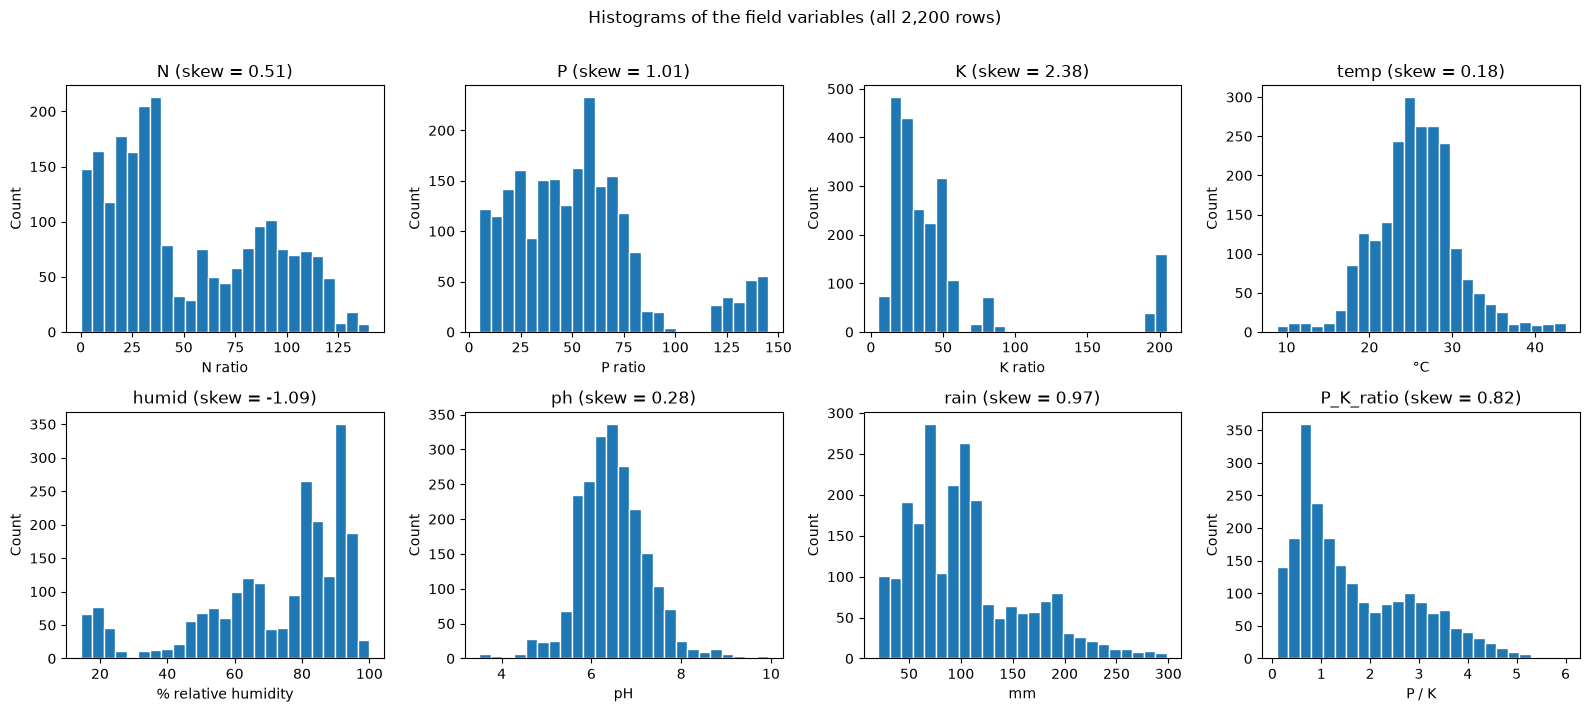

Skewness of row-level variables:
N            0.510000
P            1.011000
K            2.375000
temp         0.185000
humid       -1.092000
ph           0.284000
rain         0.966000
P_K_ratio    0.824000
dtype: float64


In [10]:
row_level = ["N", "P", "K", "temp", "humid", "ph", "rain", "P_K_ratio"]
row_level = [c for c in row_level if c in df]

display(df[row_level].describe())

UNITS = {"N": "N ratio", "P": "P ratio", "K": "K ratio", "temp": "°C", "humid": "% relative humidity",
         "ph": "pH", "rain": "mm", "P_K_ratio": "P / K"}

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), row_level):
    ax.hist(df[col], bins=25, edgecolor="white")
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
    ax.set_xlabel(UNITS.get(col, col)); ax.set_ylabel("Count")
for ax in axes.flatten()[len(row_level):]:
    ax.axis("off")
fig.suptitle("Histograms of the field variables (all 2,200 rows)", y=1.01)
plt.tight_layout()
plt.show()

print("Skewness of row-level variables:")
print(df[row_level].skew().round(3))

### 2.7 Transformations

We use two transformations:

* **Box-Cox** finds the power λ that makes a strictly positive variable closest to normal; we report the nearest rung of **Tukey's ladder** (2 = square, 1 = none, 0.5 = square root, 0 = log, −1 = reciprocal) so the choice is easy to explain.
* Rule: transform a **strictly positive continuous predictor** when |skewness| > 0.75.
* `ca_area_ha` and `ca_farm_value` are mostly zeros (crops not matched in the selected Statistics Canada tables), so Box-Cox is impossible; we use **log(x + 1)**, the log rung of Tukey's ladder shifted by 1 so that 0 stays 0.
* The response `N` is **not** transformed so its coefficients stay in the original units (and N contains zeros, so Box-Cox cannot be applied).

New columns get a `_bc` (Box-Cox) or `_log` suffix; the originals are kept for reference but **only one version of each variable** is offered to the models.

,variable,skew_before,lambda,nearest_tukey_rung,skew_after
0,P,1.011000,0.391000,0.5 (square root),-0.030000
1,K,2.375000,-0.335000,-0.5 (reciprocal square root),-0.030000
2,temp,0.185000,NaN,not transformed,0.185000
3,humid,-1.092000,2.118000,2 (square),-0.472000
4,ph,0.284000,NaN,not transformed,0.284000
5,rain,0.966000,0.217000,0 (log),-0.014000
6,P_K_ratio,0.824000,0.247000,0 (log),-0.052000


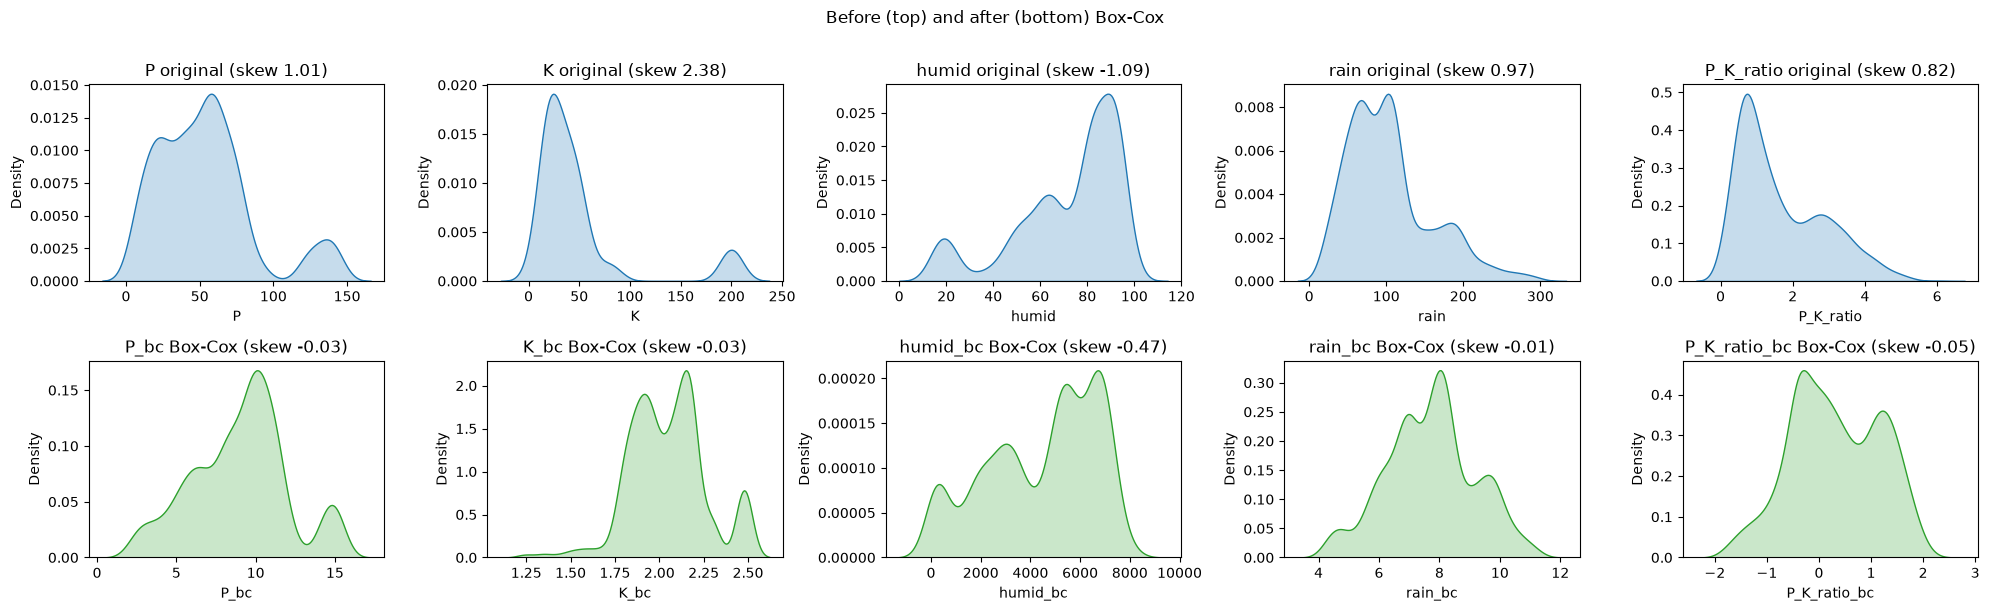

In [11]:

TUKEY = {2: "square", 1: "none", 0.5: "square root", 0: "log", -0.5: "reciprocal square root",
         -1: "reciprocal", -2: "reciprocal square"}

candidates = [c for c in ["P", "K", "temp", "humid", "ph", "rain", "P_K_ratio"] if c in df]
transform_log = []
use_version = {}     # variable -> column that the models should use

for c in candidates:
    skew = df[c].skew()
    if abs(skew) > 0.75 and (df[c] > 0).all():
        transformed, lam = boxcox(df[c])
        df[c + "_bc"] = transformed
        rung = min(TUKEY, key=lambda p: abs(p - lam))
        transform_log.append({"variable": c, "skew_before": skew, "lambda": lam,
                              "nearest_tukey_rung": f"{rung} ({TUKEY[rung]})",
                              "skew_after": pd.Series(transformed).skew()})
        use_version[c] = c + "_bc"
    else:
        transform_log.append({"variable": c, "skew_before": skew, "lambda": np.nan,
                              "nearest_tukey_rung": "not transformed", "skew_after": skew})
        use_version[c] = c

for c in ["ca_area_ha", "ca_farm_value"]:
    df[c + "_log"] = np.log1p(df[c])
    use_version[c] = c + "_log"

display(pd.DataFrame(transform_log).round(3))

bc_cols = [v for v in use_version.values() if v.endswith("_bc")]
if bc_cols:
    fig, axes = plt.subplots(2, len(bc_cols), figsize=(4 * len(bc_cols), 6), squeeze=False)
    for i, c in enumerate(bc_cols):
        orig = c.replace("_bc", "")
        sns.kdeplot(df[orig], fill=True, ax=axes[0, i])
        axes[0, i].set_title(f"{orig} original (skew {df[orig].skew():.2f})")
        sns.kdeplot(df[c], fill=True, ax=axes[1, i], color="tab:green")
        axes[1, i].set_title(f"{c} Box-Cox (skew {df[c].skew():.2f})")
    fig.suptitle("Before (top) and after (bottom) Box-Cox", y=1.01)
    plt.tight_layout()
    plt.show()

### 2.8 Converting categorical variables

* **Nominal variable (`label`)** → dummy (indicator)
  variables with k − 1 columns (`drop_first=True`).
  The 22 crop labels produce 21 dummy variables,
  avoiding perfect collinearity with the intercept.

* **Ordinal variable (`ph_class`)** → ordered codes
  0 = acidic, 1 = neutral, 2 = alkaline.

* **Binary flags** (`is_legume`, `grown_in_canada`)
  are already encoded as 0 and 1.

The `life_form` and `eco_category` variables were
removed in Section 2.5 because of missing values.

The original categorical columns are retained for
the train/test comparison using the Chi-square test.

In [23]:
nominal = ["label"]                                     # the only nominal variable left after 2.5
df["label"] = df["label"].astype("category")
df["ph_class_ord"] = df["ph_class"].cat.codes           # 0 acidic, 1 neutral, 2 alkaline

dummies = pd.get_dummies(df["label"], prefix="label", drop_first=True, dtype=int)
df = df.drop(columns=dummies.columns, errors="ignore")   # avoids duplicate columns if this cell is re-run
df = pd.concat([df, dummies], axis=1)

label_dummies = dummies.columns.tolist()
print(f"{len(label_dummies)} label dummies:", label_dummies)

21 label dummies: ['label_banana', 'label_blackgram', 'label_chickpea', 'label_coconut', 'label_coffee', 'label_cotton', 'label_grapes', 'label_jute', 'label_kidneybeans', 'label_lentil', 'label_maize', 'label_mango', 'label_mothbeans', 'label_mungbean', 'label_muskmelon', 'label_orange', 'label_papaya', 'label_pigeonpeas', 'label_pomegranate', 'label_rice', 'label_watermelon']


### 2.9 Final study file

`study` holds the usable variables (one version of each transformed variable, all categoricals converted). It is saved to `crop_study_file.csv`.

The study file contains **27 usable variables before dummy coding and 47 columns after**: 26 non-categorical variables plus the 21 crop-name dummies.

In [24]:
binary_flags = ["is_legume", "grown_in_canada"]
eco_numeric_cols = [c for c in df.columns if c.startswith("eco_") and pd.api.types.is_numeric_dtype(df[c])]

row_level_vars = ["N"] + [use_version[c] for c in ["P", "K", "temp", "humid", "ph", "rain", "P_K_ratio"]] \
                 + ["ph_class_ord"]
crop_level_vars = eco_numeric_cols + [use_version["ca_area_ha"], use_version["ca_farm_value"]] + binary_flags

study_cols = row_level_vars + crop_level_vars + label_dummies
study = df[study_cols].copy()
study.to_csv("crop_study_file.csv", index=False)

n_vars_before_dummies = len(row_level_vars) + len(crop_level_vars) + len(nominal)
print(f"Usable variables before dummy coding : {n_vars_before_dummies}")
print(f"Usable columns in study file          : {study.shape[1]}")
assert study.shape[1] >= 25, "Study file must contain at least 25 usable variables"
print("Missing values in study file:", int(study.isna().sum().sum()))
study.info()

Usable variables before dummy coding : 27
Usable columns in study file          : 47
Missing values in study file: 0
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 47 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   N                  2200 non-null   int64  
 1   P_bc               2200 non-null   float64
 2   K_bc               2200 non-null   float64
 3   temp               2200 non-null   float64
 4   humid_bc           2200 non-null   float64
 5   ph                 2200 non-null   float64
 6   rain_bc            2200 non-null   float64
 7   P_K_ratio_bc       2200 non-null   float64
 8   ph_class_ord       2200 non-null   int8   
 9   eco_topt_min       2200 non-null   float64
 10  eco_topt_max       2200 non-null   float64
 11  eco_tabs_min       2200 non-null   float64
 12  eco_tabs_max       2200 non-null   float64
 13  eco_ropt_min       2200 non-null   float64
 14  eco_ropt_max  

### 2.10 Data sources, rationale and transformations

**Why augment at crop level.** Our Crop Recommendation dataset has no location or date column; the only key that links it to other data is the crop name (`label`). We therefore chose sources that describe *crops*, joined many-to-one on `label`.

**FAO EcoCrop.** Developed by the Food and Agriculture Organization of the UN, EcoCrop records the optimal and absolute temperature, rainfall and soil-pH limits, crop-cycle length, life form and category for thousands of plant species. It is authoritative, global (not tied to any one country) and directly answers the question our project asks: *are these conditions right for this crop?* We matched crops by scientific name to avoid ambiguity (e.g., "gram", "melon"). Crop cycle, life form and category were requested but dropped in 2.5 because FAO has no usable value for at least one of our crops, leaving 12 temperature, rainfall and pH requirements plus the derived temperature-tolerance width.

**Statistics Canada (tables 32-10-0359-01,
32-10-0364-01, 32-10-0365-01).** These official
tables provide harvested or cultivated area and
farm value by crop. They help us understand each
crop's relevance to Canadian agriculture.

A zero indicates that a matching record or recent
value was unavailable in the selected tables.
It does not necessarily mean that the crop is
not grown in Canada. Available values from the
latest five-year period are averaged to reduce
year-to-year variation.

**Domain-knowledge variable.** `is_legume` comes from botany (family Fabaceae). Legumes host nitrogen-fixing bacteria, which is directly relevant to our dependent variable, soil nitrogen.

**Transformations.**
* Box-Cox / Tukey's ladder was applied to strictly positive, clearly skewed predictors (rule: |skew| > 0.75). The table above shows λ, the nearest Tukey rung and the skewness before and after. As the slides note, simple prediction works best with variables that are close to normally distributed and linearly related; reducing skew moves the variables in that direction and reduces the pull of extreme values.
* log(x + 1) was used for the zero-heavy Canadian area and value variables because Box-Cox requires positive values.
* Categorical variables were dummy coded (k − 1) and `ph_class` was ordinal-coded, as described in 2.8.
* Any EcoCrop field missing for one of our crops was dropped rather than filled, so no values are estimated.

**Caveat we keep in mind for modelling.** Every crop-level variable has only 22 distinct values (one per crop). They are therefore perfectly explained by the `label` dummies, so the two groups must **not** be used in the same regression model. The regression sections use the crop-level variables (they describe *why* crops differ); the `label` dummies remain in the study file for other parts of the project.

## 3. Split into Training and Test Sets

We use an **80/20 random split** with a fixed seed. The training set is used to build every model; the test set is only used to validate them.

In [14]:
train, test = train_test_split(df, test_size=TEST_SIZE, random_state=RANDOM_STATE)

print("Train:", train.shape)
print("Test :", test.shape)

display(train[row_level_vars + nominal].describe(include="all").T)
display(test[row_level_vars + nominal].describe(include="all").T)


Train: (1760, 56)
Test : (440, 56)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
N,1760.000000,NaN,NaN,NaN,50.046023,36.886326,0.000000,21.000000,36.000000,84.000000,140.000000
P_bc,1760.000000,NaN,NaN,NaN,8.986511,2.936144,2.241391,6.855902,9.343815,10.761134,15.351905
K_bc,1760.000000,NaN,NaN,NaN,2.042671,0.214015,1.243882,1.890356,2.039672,2.168303,2.482318
temp,1760.000000,NaN,NaN,NaN,25.631198,5.012170,8.825675,22.810495,25.605637,28.568106,43.675493
humid_bc,1760.000000,NaN,NaN,NaN,4405.322036,2211.819981,130.786704,2729.648337,5117.710161,6462.110271,8059.777557
ph,1760.000000,NaN,NaN,NaN,6.460711,0.772545,3.504752,5.965508,6.419778,6.910487,9.935091
rain_bc,1760.000000,NaN,NaN,NaN,7.695137,1.473640,4.254883,6.739465,7.758264,8.522621,11.268275
P_K_ratio_bc,1760.000000,NaN,NaN,NaN,0.327331,0.854023,-1.810185,-0.341437,0.251036,1.089614,2.253014
ph_class_ord,1760.000000,NaN,NaN,NaN,0.530114,0.646152,0.000000,0.000000,0.000000,1.000000,2.000000
label,1760,22,mungbean,88,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
N,440.000000,NaN,NaN,NaN,52.575000,37.013989,0.000000,22.000000,39.000000,85.000000,133.000000
P_bc,440.000000,NaN,NaN,NaN,8.949216,3.205139,2.241391,6.822666,9.343815,10.912991,15.351905
K_bc,440.000000,NaN,NaN,NaN,2.061484,0.221760,1.347000,1.908085,2.077287,2.189878,2.482318
temp,440.000000,NaN,NaN,NaN,25.556429,5.270468,10.164313,22.636226,25.553100,28.445080,43.302049
humid_bc,440.000000,NaN,NaN,NaN,4569.453329,2169.843035,140.768597,2933.834953,5151.155072,6549.621190,8117.468693
ph,440.000000,NaN,NaN,NaN,6.504555,0.779379,3.711059,5.999210,6.458960,6.958079,9.392695
rain_bc,440.000000,NaN,NaN,NaN,7.748961,1.373179,4.240788,6.856149,7.861816,8.462723,11.237747
P_K_ratio_bc,440.000000,NaN,NaN,NaN,0.228482,0.861477,-1.810185,-0.366186,0.198223,0.939230,2.053442
ph_class_ord,440.000000,NaN,NaN,NaN,0.565909,0.644035,0.000000,0.000000,0.000000,1.000000,2.000000
label,440,22,banana,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Are the training and test sets comparable?

* **Numeric variables – Kolmogorov-Smirnov (KS) test.**
  H₀: Both samples come from the same distribution.

* **Categorical variables – Chi-square test.**
  H₀: Category proportions are the same in both sets.

At a significance level of 0.05:

* p > 0.05: No statistically significant difference detected.
* p ≤ 0.05: A statistically significant difference detected.

Similar crop proportions support the comparability
of crop-level variables but do not guarantee
identical distributions.

In [15]:
numeric_vars = [c for c in row_level_vars + crop_level_vars if c not in binary_flags + ["ph_class_ord"]]  

ks_rows = []
for var in numeric_vars:
    stat, p = ks_2samp(train[var], test[var])
    ks_rows.append({"variable": var, "train_mean": train[var].mean(), "test_mean": test[var].mean(),
                    "KS_stat": stat, "p_value": p,
                    "comparable": "yes" if p > ALPHA else "NO"})
ks_table = pd.DataFrame(ks_rows)
display(ks_table.round(4))

chi_rows = []
for var in nominal + ["ph_class"] + binary_flags:
    trainc = train[var].value_counts().sort_index()
    testc = test[var].value_counts().sort_index()
    table = pd.DataFrame([trainc, testc], index=["Train", "Test"]).fillna(0)
    table = table.loc[:, table.sum() > 0]
    chi2, p, dof, expected = chi2_contingency(table)
    chi_rows.append({"variable": var, "levels": table.shape[1], "chi2": chi2, "dof": dof,
                     "p_value": p, "comparable": "yes" if p > ALPHA else "NO"})
chi_table = pd.DataFrame(chi_rows)
display(chi_table.round(4))

print("Crop counts in each set:")
display(pd.DataFrame({"train": train["label"].value_counts().sort_index(),
                      "test": test["label"].value_counts().sort_index()}).T)

flagged = ks_table.loc[ks_table["comparable"] == "NO", "variable"].tolist() + \
          chi_table.loc[chi_table["comparable"] == "NO", "variable"].tolist()
print("Variables with a significant train/test difference:", flagged or "none")

,variable,train_mean,test_mean,KS_stat,p_value,comparable
0,N,50.046000,52.575000,0.050600,0.322700,yes
1,P_bc,8.986500,8.949200,0.050000,0.335800,yes
2,K_bc,2.042700,2.061500,0.054000,0.251300,yes
3,temp,25.631200,25.556400,0.033000,0.831900,yes
4,humid_bc,4405.322000,4569.453300,0.047700,0.391900,yes
5,ph,6.460700,6.504600,0.042600,0.536600,yes
6,rain_bc,7.695100,7.749000,0.055700,0.220300,yes
7,P_K_ratio_bc,0.327300,0.228500,0.064200,0.107000,yes
8,eco_topt_min,19.421600,19.586400,0.045500,0.453300,yes
9,eco_topt_max,31.756200,31.838600,0.019900,0.998800,yes


,variable,levels,chi2,dof,p_value,comparable
0,label,22,24.125000,21,0.287000,yes
1,ph_class,3,2.046800,2,0.359400,yes
2,is_legume,2,3.146100,1,0.076100,yes
3,grown_in_canada,2,0.887000,1,0.346300,yes


Crop counts in each set:


label,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,lentil,maize,mango,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon
train,79,73,76,78,78,78,75,75,80,87,83,85,85,80,88,84,76,77,84,77,84,78
test,21,27,24,22,22,22,25,25,20,13,17,15,15,20,12,16,24,23,16,23,16,22


Variables with a significant train/test difference: none


#### Visual comparison of the two sets

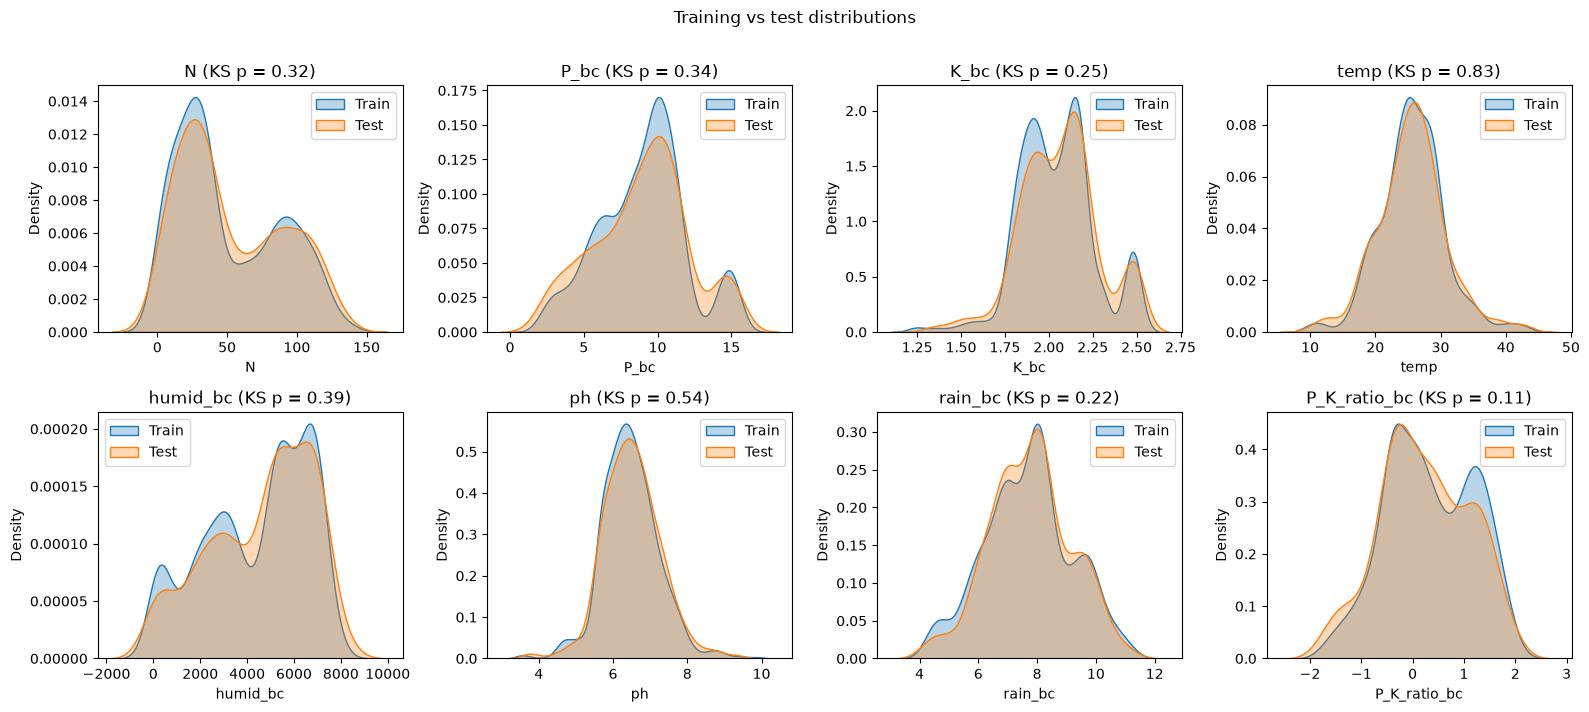

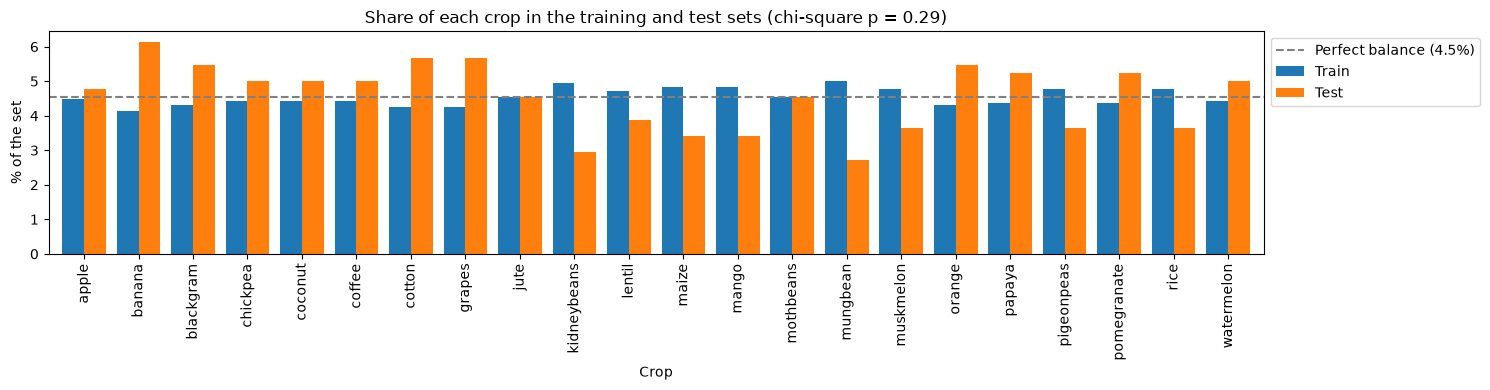

In [16]:
cont = [c for c in row_level_vars if c != "ph_class_ord"]
ks_p = ks_table.set_index("variable")["p_value"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flatten(), cont):
    sns.kdeplot(train[col], ax=ax, fill=True, alpha=0.3, label="Train")
    sns.kdeplot(test[col], ax=ax, fill=True, alpha=0.3, label="Test")
    ax.set_title(f"{col} (KS p = {ks_p[col]:.2f})")
    ax.legend()
for ax in axes.flatten()[len(cont):]:
    ax.axis("off")
fig.suptitle("Training vs test distributions", y=1.01)
plt.tight_layout()
plt.show()

shares = pd.DataFrame({"Train": train["label"].value_counts(normalize=True),
                       "Test": test["label"].value_counts(normalize=True)}).sort_index() * 100
ax = shares.plot.bar(figsize=(15, 4), width=0.8)
ax.axhline(100 / 22, color="grey", linestyle="--", label="Perfect balance (4.5%)")
ax.set_ylabel("% of the set"); ax.set_xlabel("Crop")
ax.set_title(f"Share of each crop in the training and test sets (chi-square p = {chi_table.set_index('variable').loc['label', 'p_value']:.2f})")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
plt.show()

#### Train/test comparison — Summary

**What we did and why.** A regression model always fits the data it was built on better than new data, so its accuracy has to be measured on observations it has not seen. We randomly split the 2,200 rows into a training set of 1,760 (80%) and a test set of 440 (20%). The fixed seed (`RANDOM_STATE = 6174`) makes the split reproducible. Every model is built on the training set only, and the test set is used only to check prediction error.

A test result is only meaningful if the two sets come from the same population, so we compared them variable by variable. We used the KS test for numeric variables because it compares whole distributions, not just means, and the Chi-square test for categorical and binary variables because it compares category proportions. 

**Results.**
* All 23 numeric variables pass the KS test at the 0.05 level.
* All four categorical and binary variables pass the Chi-square test.
* The crop mix is comparable between the two sets (p = 0.287).
* The legume indicator has the lowest p-value (0.076): legumes make up 28% of the test set compared with 33% of the training set. This is not statistically significant, but it is the largest difference between the sets and is relevant to Model B in Section 5.

No statistically significant differences were detected, so the two sets are comparable for regression analysis.

**Limitations.**
* The crop-level variables repeat for every row of the same crop, and every crop appears in both sets. The test therefore measures prediction for new observations of known crops, not for crops the model has never seen.
* The Box-Cox transformations were fitted on all the data before the split, so the test set had a small influence on the chosen λ values.

## 4. Dependent Variable

**Y = `N`, the soil nitrogen ratio recorded in the dataset.**

* **Business question:** Which crop characteristics
  and growing conditions are associated with soil
  nitrogen levels, and how accurately can we predict N?

* **Why N is a suitable regression target:** It is a
  numerical variable ranging from 0 to 140 and varies
  considerably between crops. The augmented variables,
  such as legume status and environmental requirements,
  provide additional predictors for the analysis.

* **Leakage check:** No predictor is directly calculated
  from N. The P_K_ratio uses phosphorus and potassium
  rather than nitrogen.

The analysis identifies associations with soil nitrogen
levels, not actual fertilizer requirements.

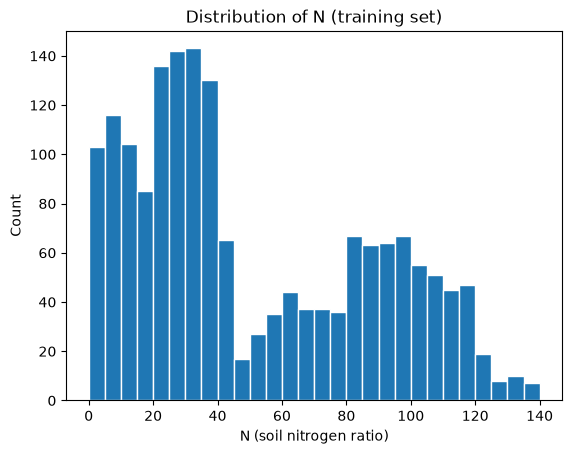

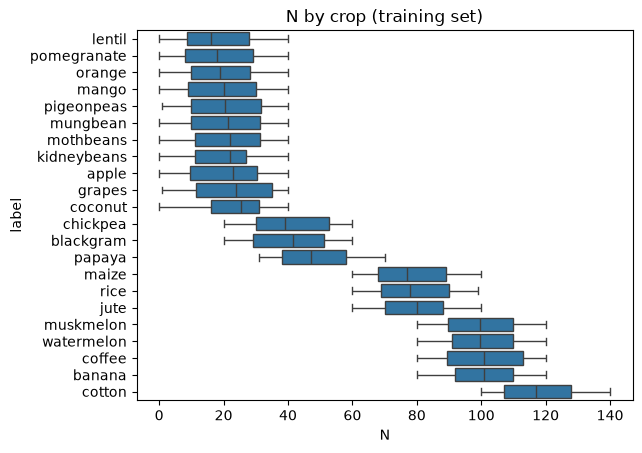

count   1760.000000
mean      50.046023
std       36.886326
min        0.000000
25%       21.000000
50%       36.000000
75%       84.000000
max      140.000000
Name: N, dtype: float64


In [25]:
Y = "N"

plt.hist(train[Y], bins=28, range=(0, 140), edgecolor="white")
plt.title("Distribution of N (training set)")
plt.xlabel("N (soil nitrogen ratio)"); plt.ylabel("Count")
plt.show()

sns.boxplot(data=train, x=Y, y="label", order=train.groupby("label")[Y].median().sort_values().index)
plt.title("N by crop (training set)")
plt.show()

print(train[Y].describe())

### Correlation with N (training set only)

Spearman is used because several variables are skewed, binary or ordinal. Pearson is shown beside it because simple linear regression fits a straight line, so it is the Pearson correlation that tells us how much a single predictor can explain (R² = Pearson r²).

,pearson_r,spearman_r
is_legume,-0.461000,-0.420000
K,-0.129000,0.220000
P,-0.233000,-0.166000
ph,0.095000,0.140000
humid,0.202000,0.079000
temp,0.019000,0.018000
rain,0.067000,0.018000


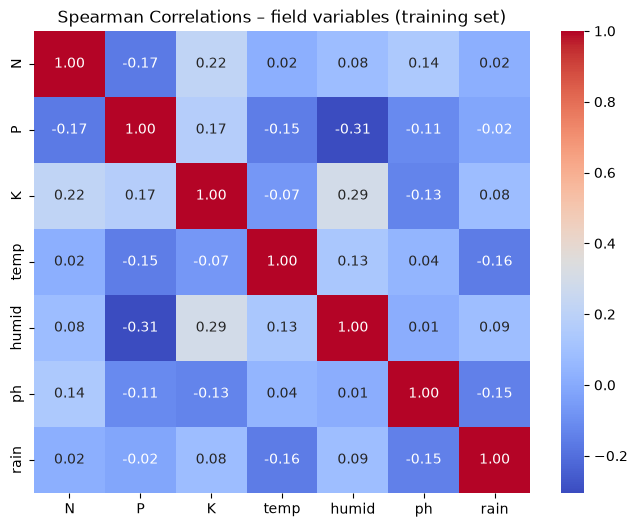

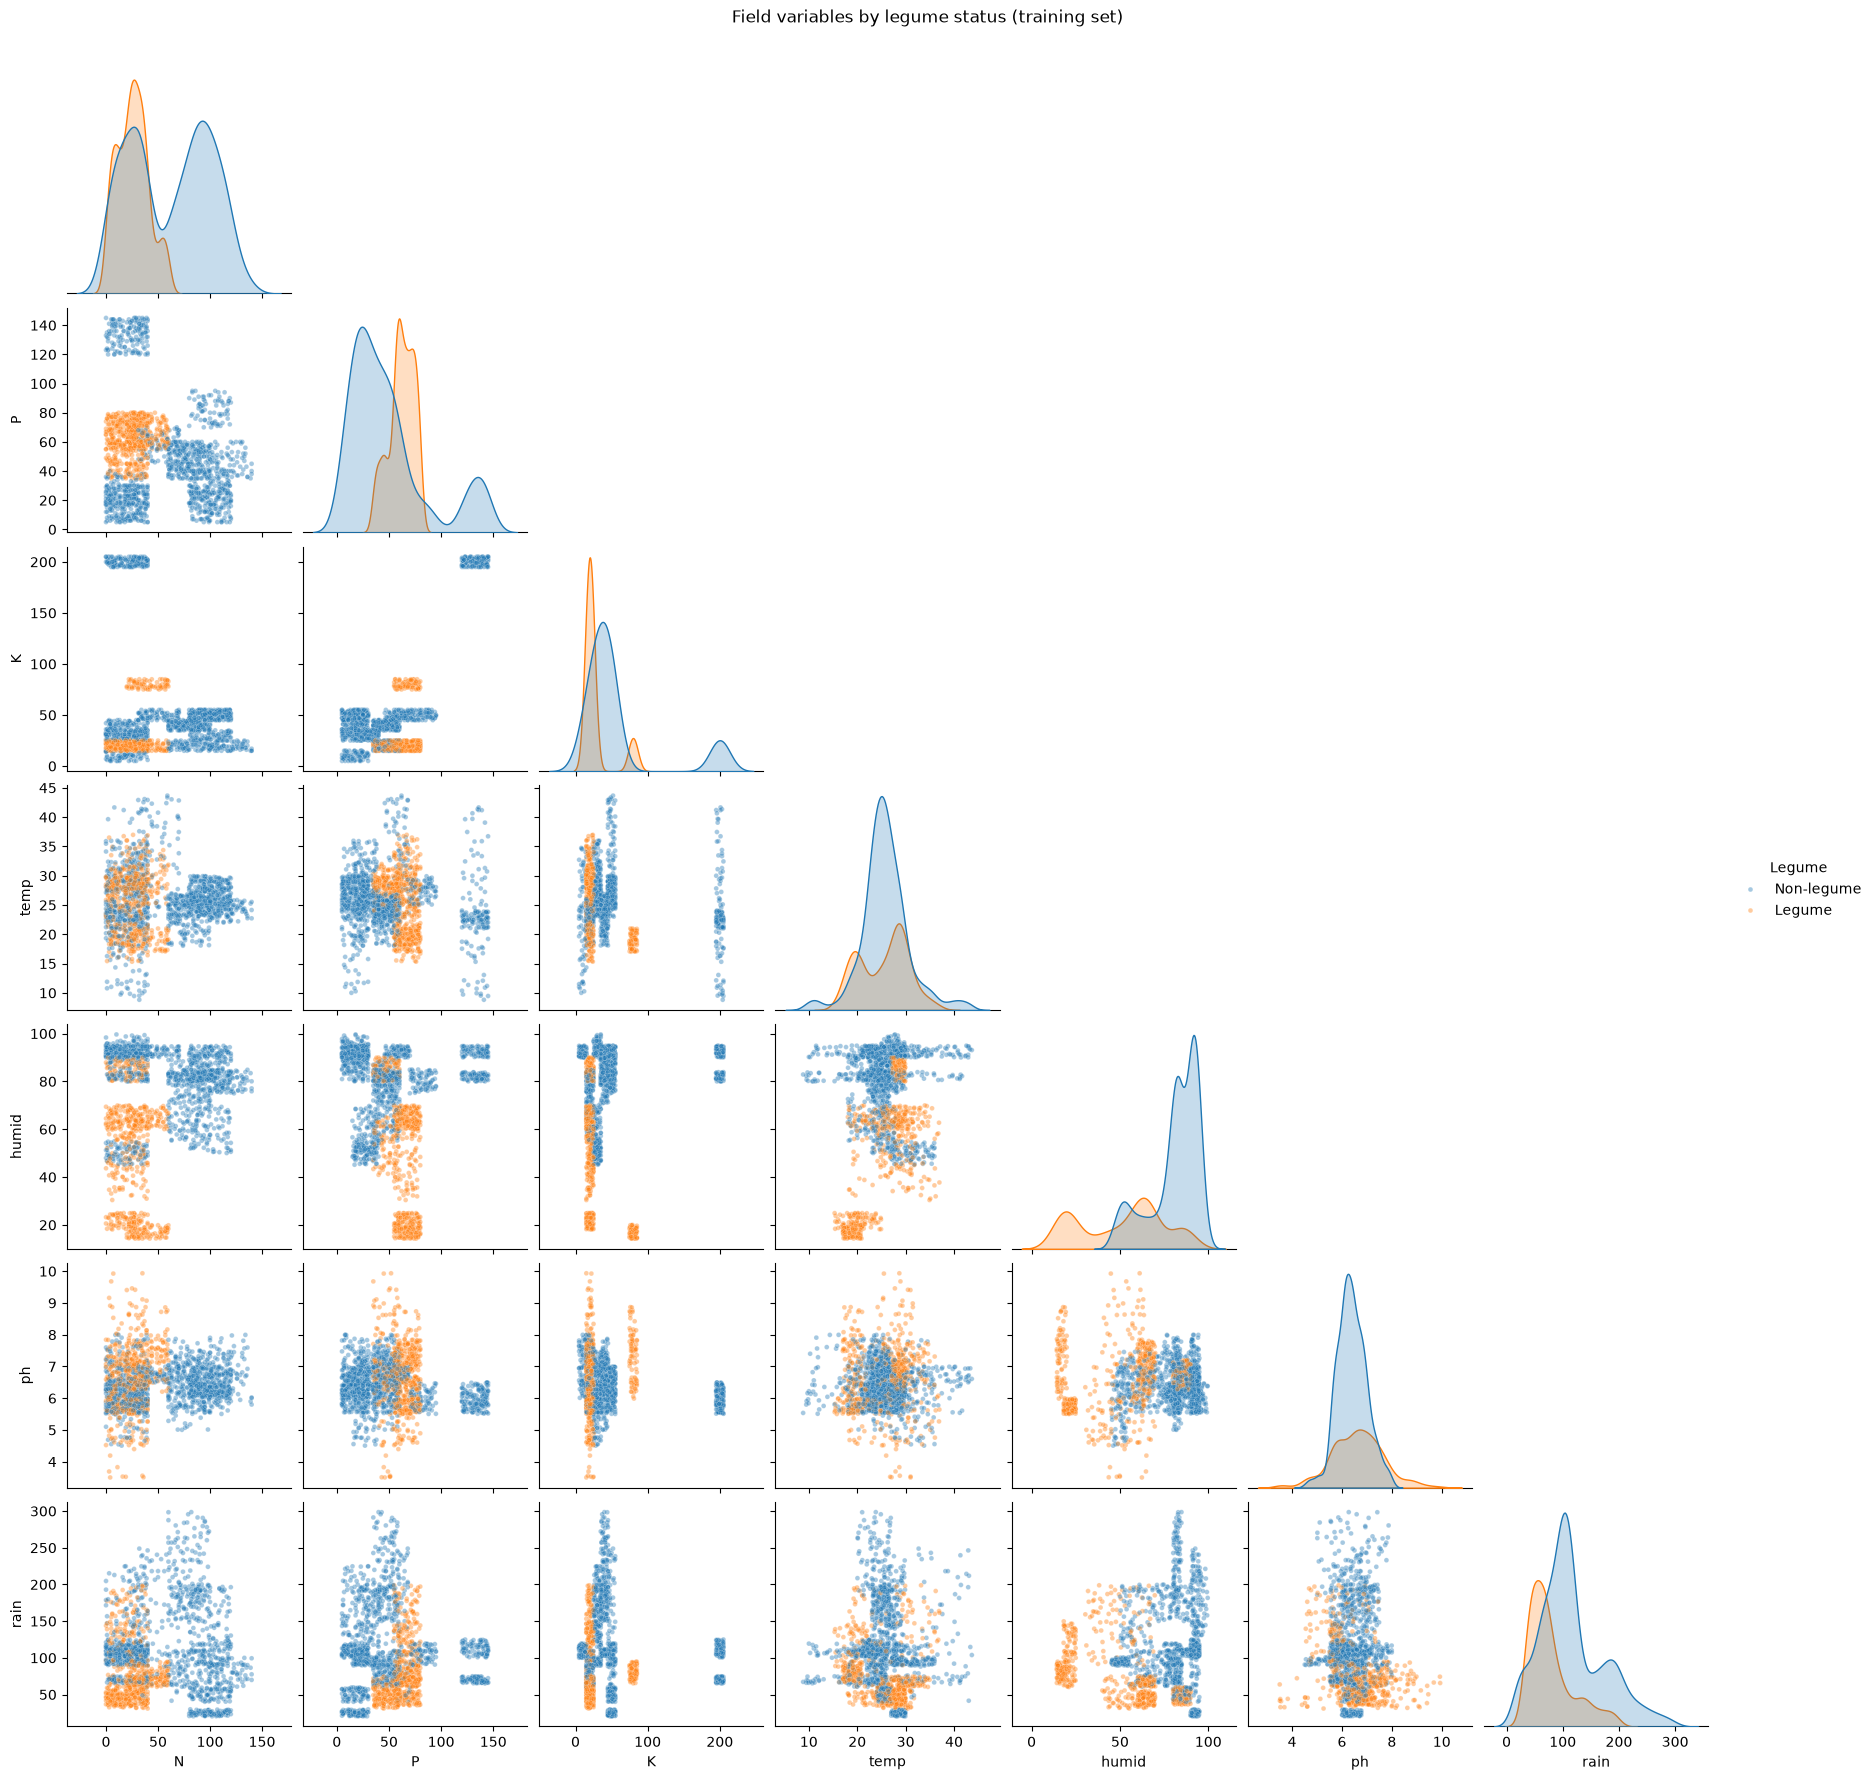

In [18]:
field_vars = ["N", "P", "K", "temp", "humid", "ph", "rain"]

corr_table = pd.DataFrame({
    "pearson_r": train[field_vars + ["is_legume"]].corr()["N"],
    "spearman_r": train[field_vars + ["is_legume"]].corr(method="spearman")["N"],
}).drop("N").sort_values("spearman_r", key=abs, ascending=False)
display(corr_table.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(train[field_vars].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Spearman Correlations – field variables (training set)")
plt.show()

pair_data = train[field_vars].assign(Legume=train["is_legume"].map({0: "Non-legume", 1: "Legume"}))
g = sns.pairplot(pair_data, hue="Legume", corner=True, plot_kws={"alpha": 0.4, "s": 12})
g.fig.suptitle("Field variables by legume status (training set)", y=1.02)
plt.show()

The heatmap below adds the crop-level (augmented) variables and shows N's 12 strongest Spearman correlates.

,spearman_r_with_N
eco_rabs_min,0.457000
is_legume,-0.420000
eco_tabs_min,0.404000
eco_ropt_min,0.326000
eco_topt_width,0.261000
eco_phabs_min,0.258000
K_bc,0.220000
eco_phopt_min,0.188000
eco_phabs_max,0.185000
eco_topt_max,0.180000


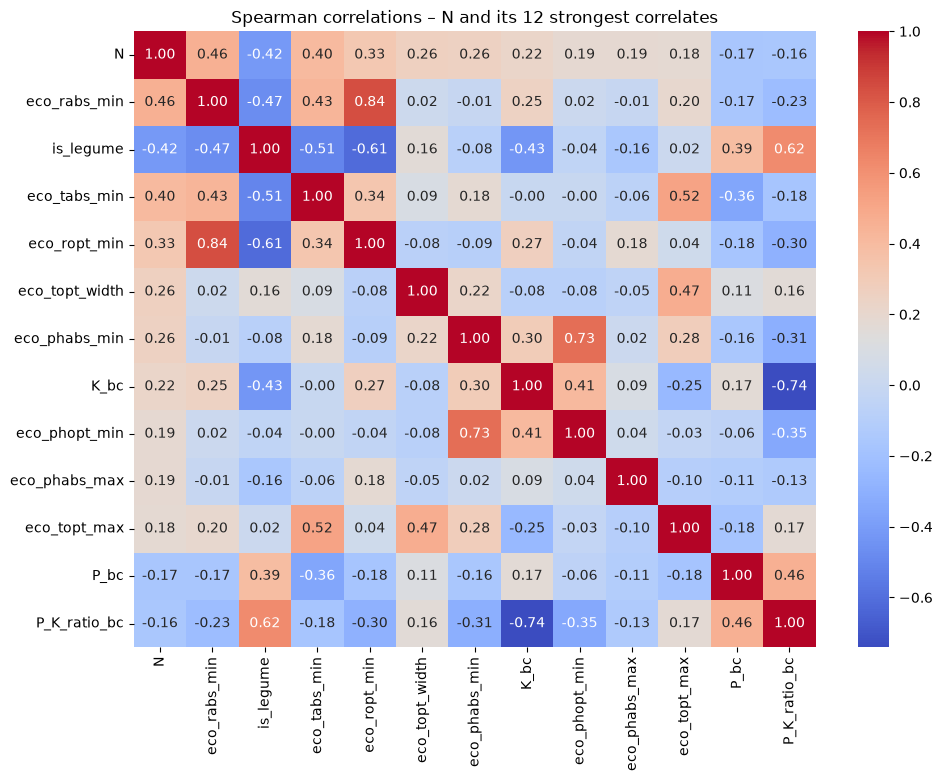

In [19]:
candidate_predictors = [c for c in row_level_vars + crop_level_vars if c != Y]

corr_y = train[candidate_predictors + [Y]].corr(method="spearman")[Y].drop(Y).sort_values(key=abs, ascending=False)
display(corr_y.to_frame("spearman_r_with_N").round(3))

top = corr_y.index[:12].tolist()
plt.figure(figsize=(11, 8))
sns.heatmap(train[[Y] + top].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Spearman correlations – N and its 12 strongest correlates")
plt.show()

## 5. Simple Linear Regression – two models

We compare two single predictors that represent the two kinds of information in our study file:

* **Model A – `N ~ P`**: a **row-level, measured** field condition from the original dataset (the soil phosphorus ratio), chosen with the candidate table below.
* **Model B – `N ~ is_legume`**: a **crop-level** characteristic added by our augmentation (is the crop a nitrogen-fixing legume?). A binary predictor is allowed in SLR: β₀ is the mean N of non-legumes and β₁ is the difference in mean N for legumes.

Both models are fitted on the **training** set only, then evaluated on the test set.

In [20]:
# Candidates: the six field variables, is_legume, and the three crop-level (augmented)  
# variables with the strongest Spearman correlation with N from Section 4  
field_candidates = ["P", "K", "temp", "humid", "ph", "rain"]  
crop_candidates = ["is_legume"] + [c for c in corr_y.index if c in crop_level_vars and c != "is_legume"][:3]  

cand_rows = []
for x in field_candidates + crop_candidates:  
    m = sm.OLS(train[Y], sm.add_constant(train[[x]])).fit()
    cand_rows.append({
        "predictor": x,
        "level": "field" if x in field_candidates else "crop",  
        "spearman_r": spearmanr(train[x], train[Y])[0],
        "slope": m.params[x],
        "adj_R2": m.rsquared_adj,
        "F_p_value": m.f_pvalue,
        "train_RMSE": rmse(train[Y], m.fittedvalues),  
    })

candidates_slr = pd.DataFrame(cand_rows)
candidates_slr["slope_sign_matches_spearman"] = np.sign(candidates_slr["slope"]) == np.sign(candidates_slr["spearman_r"])  
display(candidates_slr.sort_values("adj_R2", ascending=False).round(4))  

# How strongly the top crop-level candidates are related to legume status (training set)  
print("Spearman correlation with is_legume:") 
print(train[crop_candidates].corr(method="spearman")["is_legume"].drop("is_legume").round(3))  

# Baseline: predict the training mean of N for every test observation  
baseline_test_rmse = rmse(test[Y], np.full(len(test), train[Y].mean()))  
print(f"\nBaseline test RMSE (predict the training mean): {baseline_test_rmse:.2f}")  

,predictor,level,spearman_r,slope,adj_R2,F_p_value,train_RMSE,slope_sign_matches_spearman
7,eco_rabs_min,crop,0.457400,0.075100,0.218500,0.000000,32.589300,True
6,is_legume,crop,-0.419600,-36.255100,0.212400,0.000000,32.717500,True
8,eco_tabs_min,crop,0.403800,5.887500,0.188100,0.000000,33.218600,True
9,eco_ropt_min,crop,0.326100,0.036700,0.124000,0.000000,34.503900,True
0,P,field,-0.166100,-0.263800,0.053600,0.000000,35.863000,True
3,humid,field,0.078500,0.331900,0.040100,0.000000,36.118800,True
1,K,field,0.220000,-0.095400,0.016100,0.000000,36.567300,False
4,ph,field,0.140300,4.551600,0.008500,0.000100,36.707900,True
5,rain,field,0.018000,0.044200,0.003900,0.005200,36.793900,True
2,temp,field,0.018400,0.138700,-0.000200,0.429500,36.869300,True


Spearman correlation with is_legume:
eco_rabs_min   -0.470000
eco_tabs_min   -0.509000
eco_ropt_min   -0.612000
Name: is_legume, dtype: float64

Baseline test RMSE (predict the training mean): 37.06


#### Selection of the two simple linear regression models

We compared ten candidate predictors on the training set: the six field variables, `is_legume`, and the three augmented crop-level variables with the strongest Spearman correlation with N in Section 4. Each was judged on adjusted R², the F-test, training RMSE and whether the slope's sign agrees with the Spearman correlation.

* **Model A: N ~ P (phosphorus).** P is the best field-level predictor (adjusted R² = 0.054, training RMSE = 35.9), and its slope agrees in sign with its Spearman correlation. K has a stronger Spearman correlation but a slope of the opposite sign, so a straight line would misdescribe it. Humidity and pH explain less. We use P on its original scale so the slope is easy to interpret.

* **Model B: N ~ is_legume.** `eco_rabs_min` (FAO's minimum annual rainfall) is marginally better than `is_legume` (adjusted R² 0.219 vs 0.212; training RMSE 32.6 vs 32.7). We keep `is_legume` for three reasons:
  1. The difference is very small (0.006 in adjusted R², 0.1 in RMSE).
  2. `is_legume` has a direct biological link to soil nitrogen (legumes fix their own nitrogen), while a crop's minimum rainfall has no direct link to N. Its correlation with N partly reflects which crops are legumes: legumes in our data tolerate low rainfall (Spearman r = −0.47 with `is_legume`).
  3. As a 0/1 variable, its slope is simply the difference in mean N between legumes and other crops, which is easy to explain.

Both selected predictors are statistically significant, and their slopes agree in sign with their Spearman correlations. The crop-level variables will be considered together in the multiple regression in Section 6.

The test set is reserved for evaluating the predictive performance of the two selected models.

Spearman correlation (N vs P): -0.1661  p-value: 0.0000
Spearman correlation (N vs is_legume): -0.4196  p-value: 0.0000


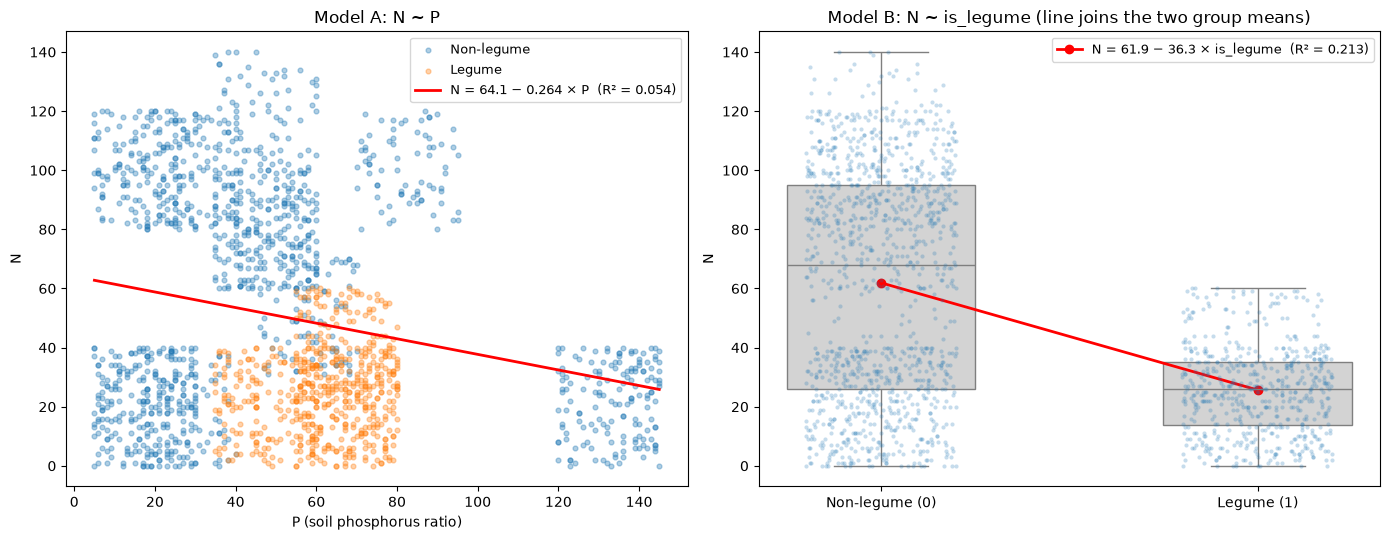

In [21]:
SLR_A = "P"
SLR_B = "is_legume"

# Scatter plots and Spearman correlations (training set)
for x in [SLR_A, SLR_B]:
    r, p = spearmanr(train[x], train[Y])
    print(f"Spearman correlation (N vs {x}): {r:.4f}  p-value: {p:.4f}")

# Preliminary models
X_a = sm.add_constant(train[[SLR_A]])
slr_a = sm.OLS(train[Y], X_a).fit()

X_b = sm.add_constant(train[[SLR_B]])
slr_b = sm.OLS(train[Y], X_b).fit()

# Model A coloured by legume status; Model B as a box plot with the line joining the two group means
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
for flag, colour, name in [(0, "tab:blue", "Non-legume"), (1, "tab:orange", "Legume")]:
    part = train[train["is_legume"] == flag]
    ax.scatter(part[SLR_A], part[Y], alpha=0.35, s=12, color=colour, label=name)
xs = np.linspace(train[SLR_A].min(), train[SLR_A].max(), 100)
ax.plot(xs, slr_a.params["const"] + slr_a.params[SLR_A] * xs, color="red", linewidth=2,
        label=f"N = {slr_a.params['const']:.1f} − {abs(slr_a.params[SLR_A]):.3f} × P  (R² = {slr_a.rsquared:.3f})")
ax.set_xlabel("P (soil phosphorus ratio)"); ax.set_ylabel("N")
ax.set_title("Model A: N ~ P")
ax.legend(fontsize=9)

ax = axes[1]
sns.boxplot(data=train, x=SLR_B, y=Y, ax=ax, width=0.5, color="lightgrey")
sns.stripplot(data=train, x=SLR_B, y=Y, ax=ax, alpha=0.25, size=3, color="tab:blue", jitter=0.2)
means = [slr_b.params["const"], slr_b.params["const"] + slr_b.params[SLR_B]]
ax.plot([0, 1], means, color="red", marker="o", linewidth=2,
        label=f"N = {means[0]:.1f} − {abs(slr_b.params[SLR_B]):.1f} × is_legume  (R² = {slr_b.rsquared:.3f})")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Non-legume (0)", "Legume (1)"])
ax.set_xlabel(""); ax.set_ylabel("N")
ax.set_title("Model B: N ~ is_legume (line joins the two group means)")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

#### Model summaries

Check the F-statistic p-value, R² / adjusted R², the t-test p-values, whether the coefficients make sense, and RMSE on train **and** test.


In [22]:
def evaluate(name, model, X_train, X_test):
    pred_trn = model.predict(X_train)
    pred_tst = model.predict(X_test)
    return {"Model": name,
            "F_stat": model.fvalue, "F_p_value": model.f_pvalue,
            "R2": model.rsquared, "Adj_R2": model.rsquared_adj,
            "n_predictors": int(model.df_model),
            "Train_RMSE": rmse(train[Y], pred_trn), "Test_RMSE": rmse(test[Y], pred_tst),
            "RMSE_gap_%": 100 * (rmse(test[Y], pred_tst) - rmse(train[Y], pred_trn)) / rmse(train[Y], pred_trn)}


print("Model A summary")
print(slr_a.summary())
print("\nModel B summary")
print(slr_b.summary())

slr_results = pd.DataFrame([
    evaluate(f"A: N ~ {SLR_A}", slr_a, X_a, sm.add_constant(test[[SLR_A]])),
    evaluate(f"B: N ~ {SLR_B}", slr_b, X_b, sm.add_constant(test[[SLR_B]])),
]).set_index("Model")
# How much better than predicting the training mean for every field
slr_results["Test_RMSE_better_than_baseline_%"] = 100 * (baseline_test_rmse - slr_results["Test_RMSE"]) / baseline_test_rmse
display(slr_results.round(4))

print("\nCoefficient t-tests:")
for name, m in [("A", slr_a), ("B", slr_b)]:
    print(name, "slope =", round(m.params.iloc[1], 4), " t =", round(m.tvalues.iloc[1], 3),
          " p =", f"{m.pvalues.iloc[1]:.2e}")

Model A summary
                            OLS Regression Results                            
Dep. Variable:                      N   R-squared:                       0.054
Model:                            OLS   Adj. R-squared:                  0.054
Method:                 Least Squares   F-statistic:                     100.7
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           4.42e-23
Time:                        22:34:32   Log-Likelihood:                -8797.6
No. Observations:                1760   AIC:                         1.760e+04
Df Residuals:                    1758   BIC:                         1.761e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         64.0868      1.640    

,F_stat,F_p_value,R2,Adj_R2,n_predictors,Train_RMSE,Test_RMSE,RMSE_gap_%,Test_RMSE_better_than_baseline_%
Model,,,,,,,,,
A: N ~ P,100.697200,0.000000,0.054200,0.053600,1,35.863000,36.102800,0.668400,2.578500
B: N ~ is_legume,475.274400,0.000000,0.212800,0.212400,1,32.717500,33.709500,3.032000,9.036500



Coefficient t-tests:
A slope = -0.2638  t = -10.035  p = 4.42e-23
B slope = -36.2551  t = -21.801  p = 1.84e-93


#### Summary – which SLR model is superior?

| Measure (training n = 1,760; test n = 440) | Model A: N ~ P | Model B: N ~ is_legume |
|---|---|---|
| F-statistic (p-value) | 100.7 (p ≈ 4.4 × 10⁻²³) | 475.3 (p ≈ 1.8 × 10⁻⁹³) |
| R² / Adjusted R² | 0.054 / 0.054 | 0.213 / 0.212 |
| Slope (t, p) | −0.264 per unit of P (t = −10.0, p < 0.001) | −36.3 (t = −21.8, p < 0.001) |
| Intercept | 64.1 | 61.9 |
| Train RMSE / Test RMSE | 35.9 / 36.1 | 32.7 / 33.7 |
| Train→test RMSE change | +0.7 % | +3.0 % |
| Test RMSE better than baseline (37.1) | 2.6 % | 9.0 % |

We compare the models using the measures covered in class:

1. **F-test:** both models are statistically significant; Model B has the much higher F-statistic (475.3 vs 100.7).

2. **R² / adjusted R²:** Model A explains about 5% of the variation in N, Model B about 21%.

3. **t-tests:** both slopes are significant (p < 0.001).

4. **Do the coefficients make sense?**
   * **Model A:** N is about 0.26 lower for each one-unit increase in P. This is an association within our data, not a biological rule. Much of it comes from the crop mix: apple and grapes, for example, combine very high P (about 130) with low N (about 22).
   * **Model B:** legumes have on average 36.3 lower N than other crops (61.9 vs 25.7). This matches biology: legumes host nitrogen-fixing bacteria in their root nodules, so they grow well at lower soil nitrogen.

5. **Statistical significance is not the same as usefulness.** With 1,760 training observations, even a weak relationship such as Model A's is highly significant. Its test RMSE (36.1) is only 2.6% better than simply predicting the training mean for every observation (37.1), so P alone has little predictive value. Model B improves on that baseline by 9.0%.

6. **RMSE on test data:** Model B has the lower test RMSE (33.7 vs 36.1). Model B's test RMSE is 3.0% higher than its training RMSE, compared with 0.7% for Model A. This reflects the crop mix rather than overfitting: the test set has fewer legumes (28% vs 33%, see Section 3), and crop averages of N vary much more among non-legumes (about 19 to 118) than among legumes (about 18 to 40), so a test set with more non-legumes has a larger error.

**Conclusion:** Model B (N ~ is_legume) is the better of the two simple models: it has the higher adjusted R² and F-statistic, the lower test RMSE, and a slope with a clear biological explanation.

However, about 79% of the variation in N is still unexplained by Model B, and its predictions are on average about 34 N off. Section 6 uses multiple linear regression to test whether combining field-level and augmented crop-level predictors improves prediction.

## 6. Multiple Linear Regression

The simple models showed that one predictor explains at most about 21% of the variation in N. Here we combine predictors,look at the correlations, fit a **full model**, reduce it with **backward selection**, build a **judgemental model** from domain knowledge, and compare all models by RMSE on the test set.

**Candidate predictors (24):** every usable variable in the study file, with three exclusions:

* **The 21 crop-name dummies** (`label_…`) are left out. Every crop-level variable has one value per crop, so it is an exact combination of the crop dummies; using both in one model would make the coefficients impossible to estimate (Section 2.10). The crop dummies are used only once, as a reference model in 6.5.
* **`eco_topt_width`** is left out because it equals `eco_topt_max − eco_topt_min` exactly, so it adds no information and would make the model unestimable.
* **Original versions of transformed variables** are not offered; only the version chosen in 2.7 is used (for example `P_bc`, not `P`).

Every model is fitted on the **training set** only and evaluated on the test set. Each model is judged on the four measures in order: the F-test p-value, adjusted R², the t-test p-values of the coefficients, and whether the coefficients are consistent with the correlation matrix. RMSE then compares the models on training and test data.

In [26]:
mlr_candidates = [c for c in row_level_vars + crop_level_vars if c not in (Y, "eco_topt_width")]
print(f"{len(mlr_candidates)} candidate predictors:")
print(mlr_candidates)

spearman_with_N = train[mlr_candidates + [Y]].corr(method="spearman")[Y]


def coef_table(model):
    # Model-level measures and a coefficient table, with a check that each coefficient's sign
    # agrees with that variable's Spearman correlation with N (slides: "check coefficients for consistency")
    print(f"F = {model.fvalue:.1f} (p = {model.f_pvalue:.2e}),  R² = {model.rsquared:.3f},  "
          f"adjusted R² = {model.rsquared_adj:.3f},  predictors = {int(model.df_model)}")
    table = pd.DataFrame({"coef": model.params, "std_err": model.bse,
                          "t": model.tvalues, "p_value": model.pvalues}).drop("Intercept")
    table["spearman_with_N"] = spearman_with_N.reindex(table.index)
    table["sign_consistent"] = np.sign(table["coef"]) == np.sign(table["spearman_with_N"])
    display(table.round(4))
    return table

24 candidate predictors:
['P_bc', 'K_bc', 'temp', 'humid_bc', 'ph', 'rain_bc', 'P_K_ratio_bc', 'ph_class_ord', 'eco_topt_min', 'eco_topt_max', 'eco_tabs_min', 'eco_tabs_max', 'eco_ropt_min', 'eco_ropt_max', 'eco_rabs_min', 'eco_rabs_max', 'eco_phopt_min', 'eco_phopt_max', 'eco_phabs_min', 'eco_phabs_max', 'ca_area_ha_log', 'ca_farm_value_log', 'is_legume', 'grown_in_canada']


### 6.1 Correlations among the candidate predictors

We start looking at the Spearman correlation matrix. For a multiple regression the correlations **between predictors** matter as well as their correlation with N: predictors that move together compete to explain the same variation (collinearity, one of the reasons for variable selection in the slides).

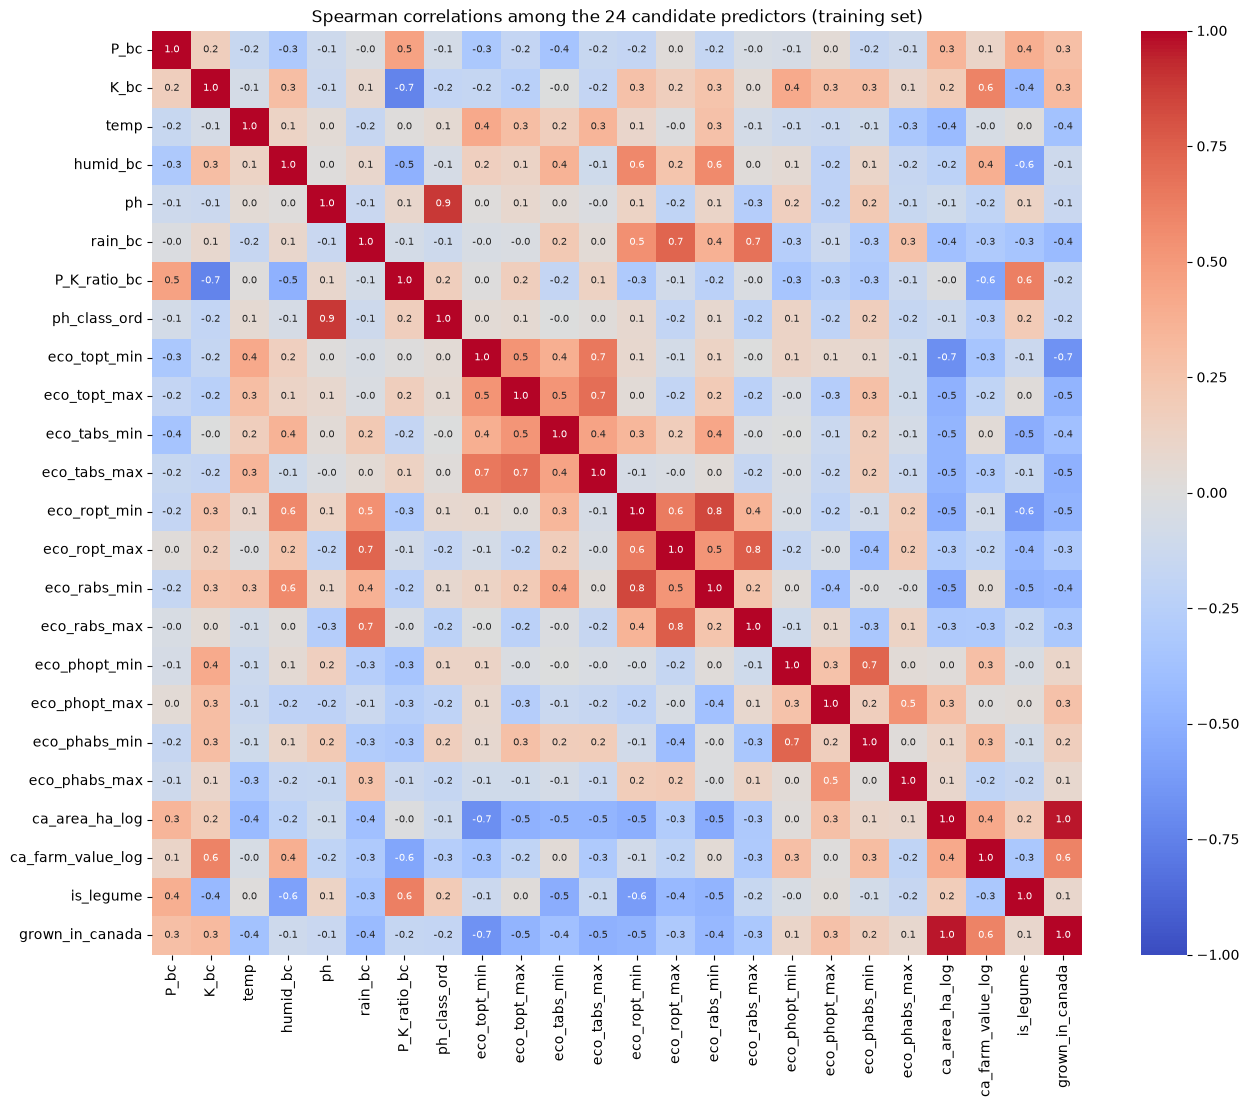

7 predictor pairs with |Spearman r| >= 0.7:


,,spearman_r
ca_area_ha_log,grown_in_canada,0.966000
ph,ph_class_ord,0.884000
eco_ropt_min,eco_rabs_min,0.843000
eco_ropt_max,eco_rabs_max,0.763000
K_bc,P_K_ratio_bc,-0.741000
eco_phopt_min,eco_phabs_min,0.732000
rain_bc,eco_ropt_max,0.728000


In [ ]:
corr_pred = train[mlr_candidates].corr(method="spearman")

plt.figure(figsize=(15, 12))
sns.heatmap(corr_pred, cmap="coolwarm", vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Spearman correlations among the 24 candidate predictors (training set)")
plt.show()

# Pairs of predictors with a strong correlation (|r| >= 0.7, "strong" )
pairs = corr_pred.where(np.triu(np.ones(corr_pred.shape, dtype=bool), k=1)).stack()
strong_pairs = pairs[pairs.abs() >= 0.7].sort_values(key=abs, ascending=False)
print(f"{len(strong_pairs)} predictor pairs with |Spearman r| >= 0.7:")
display(strong_pairs.round(3).to_frame("spearman_r"))

**What the correlations show.** Seven pairs of predictors have a strong Spearman correlation (|r| ≥ 0.7). Most are expected, because the two variables describe the same thing:

* `ca_area_ha_log` and `grown_in_canada` (r = 0.97): a crop with a positive Canadian area is, by definition, grown in Canada.
* `ph` and `ph_class_ord` (0.88): the class is built from pH.
* The FAO optimal and absolute rainfall limits (0.84 and 0.76), and the optimal and absolute minimum pH (0.73).
* `K_bc` and `P_K_ratio_bc` (−0.74): the ratio contains K.

Many other FAO variables are moderately correlated (0.5–0.7). Putting all of them into one model means several predictors compete to explain the same variation, so we expect some coefficients to become unstable. This is why we select the variables

### 6.2 Full model

All 24 candidate predictors, without exception .

In [28]:
full_formula = f"{Y} ~ " + " + ".join(mlr_candidates)
full_model = smf.ols(full_formula, data=train).fit()

full_table = coef_table(full_model)
print(f"Coefficients not significant at 0.05: {full_table.index[full_table['p_value'] > ALPHA].tolist()}")
print(f"Coefficients whose sign disagrees with the Spearman correlation: {int((~full_table['sign_consistent']).sum())} of {len(full_table)}")

RMSE_trn_full = rmse(train[Y], full_model.predict(train))
RMSE_tst_full = rmse(test[Y], full_model.predict(test))
print(f"\nTraining RMSE (Full Model): {RMSE_trn_full:.2f}")
print(f"Test RMSE (Full Model): {RMSE_tst_full:.2f}")

F = 328.0 (p = 0.00e+00),  R² = 0.819,  adjusted R² = 0.817,  predictors = 24


,coef,std_err,t,p_value,spearman_with_N,sign_consistent
P_bc,6.516300,1.173300,5.553800,0.000000,-0.166100,False
K_bc,6.900100,15.309900,0.450700,0.652300,0.220000,True
temp,0.225000,0.105200,2.138600,0.032600,0.018400,True
humid_bc,-0.003600,0.000700,-5.158400,0.000000,0.078500,False
ph,-0.002400,0.967700,-0.002500,0.998000,0.140300,False
rain_bc,-8.003400,0.567400,-14.105300,0.000000,0.018000,False
P_K_ratio_bc,-4.775500,4.340100,-1.100300,0.271300,-0.159300,True
ph_class_ord,3.333700,1.190700,2.799700,0.005200,0.074400,True
eco_topt_min,-6.684400,0.488100,-13.694700,0.000000,-0.038800,True
eco_topt_max,9.065300,0.361800,25.054600,0.000000,0.179600,True


Coefficients not significant at 0.05: ['K_bc', 'ph', 'P_K_ratio_bc', 'eco_phopt_max']
Coefficients whose sign disagrees with the Spearman correlation: 11 of 24

Training RMSE (Full Model): 15.67
Test RMSE (Full Model): 15.99


**Evaluating the full model** :

1. **F-test:** F = 328.0, p < 0.001, so the model explains far more than a guess.
2. **Adjusted R² = 0.817:** the 24 predictors together explain about 82% of the variation in N, compared with 21% for the best simple model.
3. **t-tests:** 20 of the 24 coefficients are significant at 0.05; `K_bc`, `ph`, `P_K_ratio_bc` and `eco_phopt_max` are not.
4. **Are the coefficients sensible?** Not individually. 11 of the 24 coefficients have the opposite sign to the variable's correlation with N, and several are implausibly large: `is_legume` is −143 (−36 on its own in Section 5), `grown_in_canada` is +228 and `eco_phabs_min` is −74 per pH unit. This is the collinearity expected from 6.1. Correlated predictors offset each other (for example `grown_in_canada` +228 against `ca_area_ha_log` −16), so a single coefficient no longer describes that variable's own effect.

**RMSE:** 15.67 on training and 15.99 on test data, less than half the error of Model B (33.7).

### 6.3 Backward selection

We use the backward selection function : start from the full model, remove the predictor with the largest p-value, refit, and repeat until every remaining predictor is significant at 0.05. The only addition is a line that prints each removed variable.

In [29]:
def backward_selection(data, response):

    predictors = [col for col in data.columns if col != response]

    while True:

        formula = response + " ~ " + " + ".join(predictors)

        model = smf.ols(formula, data=data).fit()

        # Get largest p-value excluding intercept
        pvals = model.pvalues.drop("Intercept")

        worst_p = pvals.max()

        if worst_p <= 0.05:
            break

        worst_term = pvals.idxmax()
        print(f"Removed {worst_term} (p = {worst_p:.4f})")

        # Handle categorical dummy variables
        base_var = worst_term.split("[")[0]

        if base_var in predictors:
            predictors.remove(base_var)
        else:
            print(f"Skipping term: {worst_term}")
            break

    return model


back_model = backward_selection(train[[Y] + mlr_candidates], Y)

print()
back_table = coef_table(back_model)
print(f"Coefficients whose sign disagrees with the Spearman correlation: {int((~back_table['sign_consistent']).sum())} of {len(back_table)}")

RMSE_trn_bck = rmse(train[Y], back_model.predict(train))
RMSE_tst_bck = rmse(test[Y], back_model.predict(test))
print(f"\nTrain RMSE (Backward Model): {RMSE_trn_bck:.2f}")
print(f"Test RMSE (Backward Model): {RMSE_tst_bck:.2f}")

Removed ph (p = 0.9980)
Removed eco_phopt_max (p = 0.8823)
Removed K_bc (p = 0.6695)

F = 375.5 (p = 0.00e+00),  R² = 0.819,  adjusted R² = 0.817,  predictors = 21


,coef,std_err,t,p_value,spearman_with_N,sign_consistent
P_bc,7.013800,0.391800,17.903800,0.000000,-0.166100,False
temp,0.232200,0.100200,2.318300,0.020500,0.018400,True
humid_bc,-0.003600,0.000600,-5.884800,0.000000,0.078500,False
rain_bc,-7.994000,0.510200,-15.668200,0.000000,0.018000,False
P_K_ratio_bc,-6.640000,1.175900,-5.646800,0.000000,-0.159300,True
ph_class_ord,3.286500,0.729600,4.504700,0.000000,0.074400,True
eco_topt_min,-6.731900,0.414400,-16.246700,0.000000,-0.038800,True
eco_topt_max,9.134700,0.305100,29.937100,0.000000,0.179600,True
eco_tabs_min,5.366300,0.276600,19.403300,0.000000,0.403800,True
eco_tabs_max,-3.890900,0.233400,-16.669600,0.000000,0.094900,False


Coefficients whose sign disagrees with the Spearman correlation: 10 of 21

Train RMSE (Backward Model): 15.67
Test RMSE (Backward Model): 15.99


**Result.** Backward selection removed three predictors, in this order: `ph` (p = 0.998), `eco_phopt_max` (p = 0.882) and `K_bc` (p = 0.670). The remaining **21 predictors** are all significant at 0.05.

1. **F-test:** F = 375.5, p < 0.001.
2. **Adjusted R² = 0.817**, slightly higher than the full model (0.8172 vs 0.8169) with three fewer predictors, so the removed variables added nothing.
3. **t-tests:** all 21 coefficients are significant (the weakest is `temp`, p = 0.021).
4. **Coefficients:** the same problem as the full model remains: 10 of the 21 signs disagree with the correlation matrix, and the large offsetting coefficients are still there.

**RMSE:** 15.67 on training and 15.99 on test data, the same as the full model.

**Why the coefficients behave this way.** Every crop-level variable has only 22 distinct values, one per crop. With 15 of them in the model, they together come close to identifying each crop, so the model is largely reproducing each crop's average N through a combination of large, offsetting coefficients. That makes it a good *predictor* for these 22 crops, but its individual coefficients cannot be read as "the effect of rainfall" or "the effect of temperature". Automatic selection is "a guide only" and may not match the aim of explaining the relationships. That is why we also build a judgemental model.

### 6.4 Judgemental model

**Judgemental** selection (based on domain knowledge) alongside backward selection, also tries its own variable combination. We choose predictors with a clear reason to be related to soil nitrogen, decided before fitting:

* `is_legume` – legumes fix their own nitrogen (the strongest single predictor with a biological explanation, Section 5).
* `eco_rabs_min` – FAO's minimum annual rainfall: crops that need more water tend to be grown at higher N in our data (the strongest Spearman correlate of N, Section 4).
* `eco_tabs_min` – FAO's minimum temperature: warm-climate crops versus crops that tolerate cold (the third-strongest crop-level correlate).

We also test whether adding the best field variable, `P_bc`, helps once these crop traits are known.

In [30]:
judge_vars = ["is_legume", "eco_rabs_min", "eco_tabs_min"]
judge_model = smf.ols(f"{Y} ~ " + " + ".join(judge_vars), data=train).fit()
judge_table = coef_table(judge_model)

RMSE_trn_jdg = rmse(train[Y], judge_model.predict(train))
RMSE_tst_jdg = rmse(test[Y], judge_model.predict(test))
print(f"Train RMSE (Judgemental Model): {RMSE_trn_jdg:.2f}")
print(f"Test RMSE (Judgemental Model): {RMSE_tst_jdg:.2f}")

# Does the best field variable add anything once the crop traits are in the model?
judge_p_model = smf.ols(f"{Y} ~ " + " + ".join(judge_vars + ["P_bc"]), data=train).fit()
print(f"\nAdding P_bc: coefficient p-value = {judge_p_model.pvalues['P_bc']:.3f}, "
      f"adjusted R² {judge_model.rsquared_adj:.3f} -> {judge_p_model.rsquared_adj:.3f}")

F = 297.7 (p = 3.10e-156),  R² = 0.337,  adjusted R² = 0.336,  predictors = 3


,coef,std_err,t,p_value,spearman_with_N,sign_consistent
is_legume,-16.290700,1.886600,-8.635000,0.000000,-0.419600,True
eco_rabs_min,0.047200,0.003600,13.271400,0.000000,0.457400,True
eco_tabs_min,3.245600,0.303500,10.692900,0.000000,0.403800,True


Train RMSE (Judgemental Model): 30.02
Test RMSE (Judgemental Model): 30.89

Adding P_bc: coefficient p-value = 0.406, adjusted R² 0.336 -> 0.336


**Evaluating the judgemental model:**

1. **F-test:** F = 297.7, p < 0.001.
2. **Adjusted R² = 0.336:** three crop traits explain about a third of the variation in N, compared with 21% for `is_legume` alone.
3. **t-tests:** all three coefficients are significant (p < 0.001).
4. **Coefficients:** all three signs agree with the correlation matrix, and each has a clear meaning:
   * **Legumes** have on average **16.3 lower N** than other crops with the same rainfall and temperature needs.
   * Each additional **100 mm** of FAO minimum annual rainfall goes with about **4.7 higher N**.
   * Each additional **1 °C** of FAO minimum temperature goes with about **3.2 higher N**.

The legume effect (−16.3) is smaller than in Model B (−36.3) because the legumes in our data are also the crops that tolerate low rainfall and cold. Part of the difference that Model B attributed to legume status is now explained by the climate variables.

**Adding P does not help:** with the three crop traits in the model, `P_bc` is not significant (p = 0.406) and adjusted R² stays at 0.336. Once the crop's characteristics are known, soil phosphorus adds no information about N.

**RMSE:** 30.02 on training and 30.89 on test data, 17% better than the baseline but about twice the error of the backward model.

### 6.5 Reference: how much of N does the crop itself explain?

Every crop-level variable has one value per crop, so no model built from them can do better than a model that simply knows **which crop** each row is. Fitting N on the 21 crop dummies (k − 1 coding from 2.8) gives that upper limit: it predicts each crop's average N. It is a **reference point**, not a candidate model, because it cannot say *why* crops differ. We also add the field variables to it, to see whether growing conditions explain any of the variation in N **within** a crop.

In [31]:
crop_model = smf.ols(f"{Y} ~ " + " + ".join(label_dummies), data=train).fit()
RMSE_trn_crop = rmse(train[Y], crop_model.predict(train))
RMSE_tst_crop = rmse(test[Y], crop_model.predict(test))
print(f"Crop only (21 dummies): adjusted R² = {crop_model.rsquared_adj:.3f}, "
      f"train RMSE = {RMSE_trn_crop:.2f}, test RMSE = {RMSE_tst_crop:.2f}")

field_cols = [use_version[c] for c in ["P", "K", "temp", "humid", "ph", "rain", "P_K_ratio"]]
crop_field_model = smf.ols(f"{Y} ~ " + " + ".join(label_dummies + field_cols), data=train).fit()
print(f"Crop + field variables: adjusted R² = {crop_field_model.rsquared_adj:.3f}, "
      f"test RMSE = {rmse(test[Y], crop_field_model.predict(test)):.2f}")

Crop only (21 dummies): adjusted R² = 0.894, train RMSE = 11.95, test RMSE = 11.67
Crop + field variables: adjusted R² = 0.894, test RMSE = 11.65


**What the reference shows.**

* Knowing only the crop gives **adjusted R² = 0.894** and a test RMSE of **11.7**. About 89% of the variation in N is simply *which crop* it is; the remaining 11% is variation between rows of the same crop.
* Adding all seven field variables (P, K, temperature, humidity, pH, rainfall, P/K) to the crop dummies leaves adjusted R² at **0.894** and test RMSE at 11.65. **Within a crop, the field conditions in our dataset explain essentially none of the variation in N.**

This puts the other models in context. The backward model (adjusted R² 0.817) captures most of what is possible from crop-level information (0.894) while using measurable crop characteristics instead of crop names. The field variables that remain in it (`P_bc`, `rain_bc`, `humid_bc`) are significant because they help tell crops apart, not because they change N within a crop. That is also why their signs disagree with their correlations.

### 6.6 Compare all models (RMSE)

As in the demo, the models are compared on training and test RMSE, together with the measures from Section 5. The best simple model (Model B) and the baseline (predicting the training mean) are included for reference.

,F_stat,F_p_value,R2,Adj_R2,n_predictors,Train_RMSE,Test_RMSE,RMSE_gap_%,Test_RMSE_better_than_baseline_%
Model,,,,,,,,,
SLR B: N ~ is_legume,475.274400,0.000000,0.212800,0.212400,1,32.717500,33.709500,3.032000,9.036500
Judgemental (3 crop traits),297.722200,0.000000,0.337200,0.336000,3,30.022700,30.888900,2.885200,16.647800
Full (24 predictors),328.026300,0.000000,0.819400,0.816900,24,15.670500,15.990500,2.041800,56.850500
Backward selection,375.481600,0.000000,0.819400,0.817200,21,15.671400,15.994700,2.062700,56.839100
Reference: crop only (21 dummies),705.976500,0.000000,0.895100,0.893800,21,11.945100,11.670300,-2.300400,68.508200


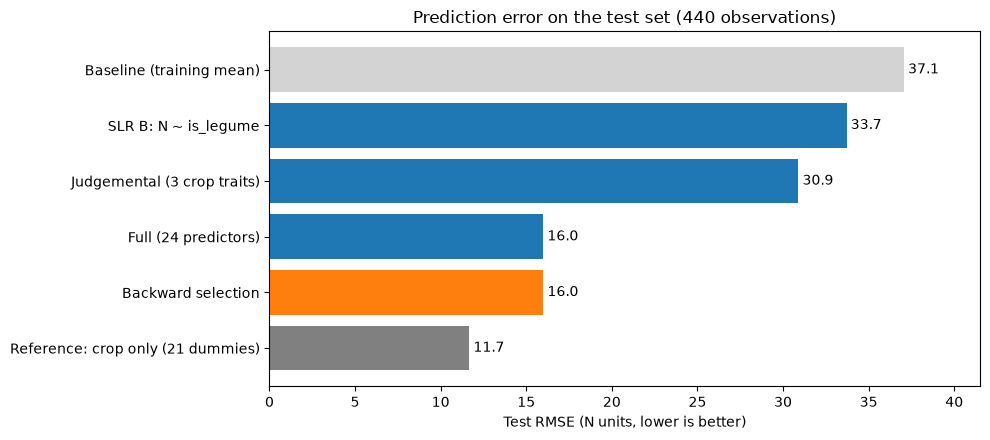

In [32]:
mlr_results = pd.DataFrame([
    evaluate(f"SLR B: N ~ {SLR_B}", slr_b, X_b, sm.add_constant(test[[SLR_B]])),
    evaluate("Judgemental (3 crop traits)", judge_model, train, test),
    evaluate("Full (24 predictors)", full_model, train, test),
    evaluate("Backward selection", back_model, train, test),
    evaluate("Reference: crop only (21 dummies)", crop_model, train, test),
]).set_index("Model")
mlr_results["Test_RMSE_better_than_baseline_%"] = 100 * (baseline_test_rmse - mlr_results["Test_RMSE"]) / baseline_test_rmse
display(mlr_results.round(4))

# Test RMSE of each model (lower is better)
fig, ax = plt.subplots(figsize=(10, 4.5))
names = ["Baseline (training mean)"] + mlr_results.index.tolist()
values = [baseline_test_rmse] + mlr_results["Test_RMSE"].tolist()
colours = ["lightgrey", "tab:blue", "tab:blue", "tab:blue", "tab:orange", "grey"]
bars = ax.barh(names[::-1], values[::-1], color=colours[::-1])
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set_xlabel("Test RMSE (N units, lower is better)")
ax.set_title("Prediction error on the test set (440 observations)")
ax.set_xlim(0, max(values) * 1.12)
plt.tight_layout()
plt.show()

#### Choosing the final model

We prefer the model that predicts best on the test set, and among models that predict about equally well (test RMSE within 2%), the simplest one (fewest predictors, Occam's Razor). The crop-only reference is not eligible because it does not use the study variables to explain N.

Models within 2% of the best test RMSE: ['Full (24 predictors)', 'Backward selection']
Final model: Backward selection


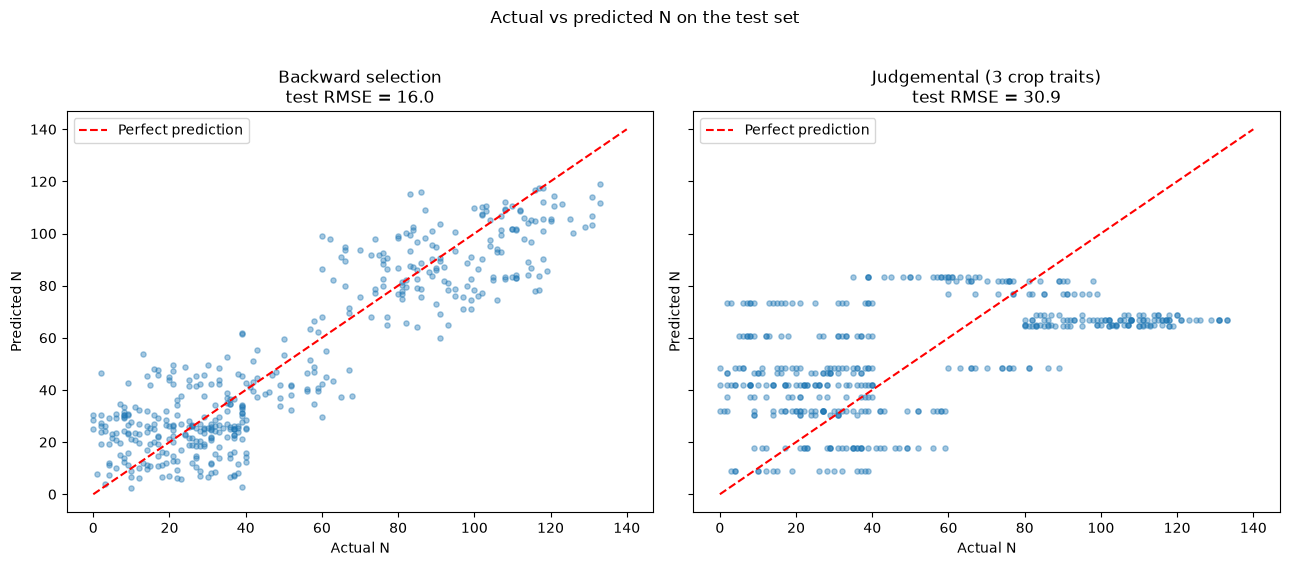

In [33]:
eligible = mlr_results.drop(index=["Reference: crop only (21 dummies)"])
best_rmse = eligible["Test_RMSE"].min()
near_best = eligible[eligible["Test_RMSE"] <= best_rmse * 1.02]
final_name = near_best.sort_values(["n_predictors", "Test_RMSE"]).index[0]
final_model = {"Full (24 predictors)": full_model, "Backward selection": back_model,
               "Judgemental (3 crop traits)": judge_model}.get(final_name, back_model)
print("Models within 2% of the best test RMSE:", near_best.index.tolist())
print("Final model:", final_name)

# Actual vs predicted N on the test set: final model and judgemental model
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, [(final_name, final_model), ("Judgemental (3 crop traits)", judge_model)]):
    pred = model.predict(test)
    ax.scatter(test[Y], pred, alpha=0.4, s=14)
    ax.plot([0, 140], [0, 140], color="red", linestyle="--", label="Perfect prediction")
    ax.set_title(f"{name}\ntest RMSE = {rmse(test[Y], pred):.1f}")
    ax.set_xlabel("Actual N"); ax.set_ylabel("Predicted N")
    ax.legend(loc="upper left")
fig.suptitle("Actual vs predicted N on the test set", y=1.02)
plt.tight_layout()
plt.show()

#### Multiple regression – discussion and final model

| Model | Predictors | Adjusted R² | Train RMSE | Test RMSE | Better than baseline |
|---|---|---|---|---|---|
| SLR B: N ~ is_legume | 1 | 0.212 | 32.7 | 33.7 | 9.0 % |
| Judgemental (3 crop traits) | 3 | 0.336 | 30.0 | 30.9 | 16.6 % |
| Full model | 24 | 0.817 | 15.7 | 16.0 | 56.9 % |
| **Backward selection (final)** | **21** | **0.817** | **15.7** | **16.0** | **56.8 %** |
| Reference: crop only | 21 dummies | 0.894 | 11.9 | 11.7 | 68.5 % |

**Final model: backward selection.** The full and backward models predict equally well (test RMSE 15.99 for both), so following Occam's Razor we choose the simpler one: the backward model drops three predictors that contributed nothing. It explains about 82% of the variation in N, and its predictions are on average about 16 N off, compared with 37 N when guessing the average and 34 N with the best single predictor.

**Validation.** The test RMSE is only about 2% higher than the training RMSE for both the full and backward models, so they are not overfitting the training rows. The test set behaves like new data from the same 22 crops, as the comparison in Section 3 predicted.

**Two models, two purposes.** It can be seen that that several models may fit about as well, and that automatic selection is a guide, not a goal. Our results show exactly this trade-off:

* The **backward model** is the best **predictor**, but its coefficients are distorted by collinearity (10 of 21 signs disagree with the correlations), so it should not be used to explain *why* N differs.
* The **judgemental model** predicts much less accurately (test RMSE 30.9), but every coefficient is significant, has the expected sign and a clear meaning. It is the better model for **explaining** N.

Both models agree on the main conclusion: crops that are legumes, need little rainfall and tolerate cold are grown at lower soil N.

**Limitations.**

* Every crop appears in both the training and test sets, so the test RMSE measures prediction for new observations of the **same 22 crops**. A crop the model has never seen could have a much larger error, particularly with the backward model, whose coefficients are tuned to these 22 crops.
* The crop-level variables have only 22 distinct values each, which limits how many of them a model can use sensibly.
* The Box-Cox transformations were fitted before the split (Section 3).
* These are associations within our dataset, not fertilizer recommendations.

## 7. Conclusion

**Problem:** which crop characteristics and growing conditions explain the soil nitrogen (N) level in our dataset, and how accurately can N be predicted?

* **Data (Section 2):** we augmented the Crop Recommendation data with FAO EcoCrop growing requirements and Statistics Canada area and value, giving 27 usable variables (47 columns after dummy coding). Skewed variables were Box-Cox transformed and categorical variables were converted.
* **Validation (Section 3):** the 80/20 split produced training and test sets with no significant differences, so test results can be trusted for the crops in our data.
* **Simple regression (Section 5):** the best single predictor, `is_legume`, explains 21% of the variation in N. Legumes average about 36 N lower than other crops, consistent with their ability to fix nitrogen.
* **Multiple regression (Section 6):** combining predictors raises this to about 82%. The final backward-selection model predicts N on the test set with an average error of about 16 N, 57% better than guessing the average. A three-variable judgemental model (legume status, minimum rainfall and minimum temperature from FAO) explains a third of the variation with clear, consistent coefficients.

**Answer to the problem.** In this dataset, N is determined mainly by the **crop**: about 89% of its variation is between crops. Crop characteristics, especially being a legume and the crop's water and temperature requirements, explain most of that difference. The measured field conditions (P, K, temperature, humidity, pH, rainfall) explain almost nothing within a crop.

